#  Intel Image Classification — CNN Trained From Scratch (No Transfer Learning)
> **Framework:** TensorFlow 2 / Keras &nbsp;|&nbsp; **Architecture:** DeepSceneNet, a custom residual CNN with SE and spatial attention (13.1 M parameters, built from scratch)  
> **Result:** **89.03 % test accuracy** and **97.37 % top-2 accuracy** on 3,000 held-out images (target was ≥ 90 %) &nbsp;|&nbsp; **Techniques:** MixUp · CutMix · Label Smoothing · Cosine LR with Warmup · Mixed Precision · TTA · Grad-CAM

---
| # | Section |
|---|---------|
| 1️. | Problem Definition & Data Understanding |
| 2️. | Data Pre-Processing & Input Pipeline |
| 3️. | Model Design in Keras |
| 4️. | Model Training (3-Phase Schedule) |
| 5️. | Evaluation & Error Analysis |
| 6️. | Reproducibility & Code Quality |

## Notebook map

This project is split into five notebooks for easier reading; each keeps the executed outputs of the full Kaggle T4 run.

| Notebook | Topic | Scope |
|---|---|---|
| [01](01_problem_definition_and_eda.ipynb) | Problem Definition & Exploratory Data Analysis | Section 1 |
| [02](02_preprocessing_and_augmentation.ipynb) | Pre-Processing & Augmentation Pipeline | Section 2 |
| [03](03_model_architecture.ipynb) | Model Design: DeepSceneNet | Section 3 |
| [04](04_training.ipynb) | Three-Phase Training | Section 4 |
| [05](05_evaluation_and_explainability.ipynb) | Evaluation, Error Analysis & Grad-CAM | Sections 5-6 |
| [00](00_full_pipeline_run_all.ipynb) | **Full pipeline - run this to reproduce everything** | Sections 1-6 |

---
## 1️⃣ Problem Definition & Data Understanding

### 1.1 Task Description
**Problem:** Multi-class image scene classification into 6 categories.

| Class | Typical Visual Cues |
|-------|-------------------|
| `buildings` | Rectangular structures, glass, concrete |
| `forest`    | Dense green foliage, trees |
| `glacier`   | Blue-white ice, snow fields |
| `mountain`  | Rocky peaks, slopes, skyline |
| `sea`       | Horizon, water, waves |
| `street`    | Roads, pavements, urban signs |

**Dataset:** Intel Image Classification - 17,034 labelled colour JPEGs at 150×150 px (14,034 train / 3,000 test; the public release also contains about 7,000 unlabelled prediction images, which are not used)  
**Challenge:** High inter-class similarity (glacier ↔ mountain, sea ↔ glacier, buildings ↔ street)  
**Approach:** Custom deep CNN trained from scratch — no pre-trained weights.

### 1.2 Install & Import Dependencies

In [ ]:
# ─── Kaggle GPU check ──────────────────────────────────────────────────────
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout[:800] if result.returncode == 0 else "No GPU detected")


Wed Mar 18 02:04:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9


In [ ]:
# ─── Standard library ─────────────────────────────────────────────────────────
import os, sys, json, random, warnings, zipfile, time, itertools
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")

# ─── Scientific / Viz ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot   as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
sns.set_theme(style="whitegrid", palette="tab10")

# ─── TensorFlow / Keras ──────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers, optimizers, callbacks
import tensorflow.keras.backend as K

# ─── Sklearn ──────────────────────────────────────────────────────────────────
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_curve, auc, average_precision_score)
from sklearn.preprocessing   import label_binarize
from sklearn.model_selection import StratifiedShuffleSplit

print(f"Python     : {sys.version.split()[0]}")
print(f"TensorFlow : {tf.__version__}")
print(f"GPU(s)     : {tf.config.list_physical_devices('GPU')}")


2026-03-18 02:04:38.016382: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773799478.412521      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773799478.520428      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773799479.494458      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773799479.494505      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773799479.494509      55 computation_placer.cc:177] computation placer alr

Python     : 3.12.12
TensorFlow : 2.19.0
GPU(s)     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.3 Global Configuration (Single Source of Truth)

In [ ]:
# ─── Reproducibility — MUST run before anything else ─────────────────────────
SEED = 42
os.environ["PYTHONHASHSEED"]       = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.backend.clear_session()

# ─── Kaggle GPU: enable memory growth ─────────────────────────────────────────
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f" GPU memory growth enabled — {len(gpus)} GPU(s) found")

# ─── Mixed precision (float16 compute, float32 variables) ─────────────────────
tf.keras.mixed_precision.set_global_policy("mixed_float16")
print(f" Mixed precision policy : {tf.keras.mixed_precision.global_policy().name}")

# ─── Auto-detect dataset path (handles any Kaggle folder structure) ───────────
import glob as _glob

def _find_class_dir(base, split_keywords):
    """Walk /kaggle/input and find the folder that contains the 6 class folders."""
    CLASSES = {"buildings","forest","glacier","mountain","sea","street"}
    for root, dirs, _ in os.walk(base):
        if CLASSES.issubset({d.lower() for d in dirs}):
            # Check the split keyword is somewhere in root path
            root_lower = root.lower()
            if any(kw in root_lower for kw in split_keywords):
                return Path(root)
    # Fallback: return first dir that has all 6 classes regardless of keyword
    for root, dirs, _ in os.walk(base):
        if CLASSES.issubset({d.lower() for d in dirs}):
            return Path(root)
    return None

_INPUT_BASE = "/kaggle/input"
_TRAIN_DIR  = _find_class_dir(_INPUT_BASE, ["seg_train", "train"])
_TEST_DIR   = _find_class_dir(_INPUT_BASE, ["seg_test",  "test", "pred"])

assert _TRAIN_DIR is not None, (
    "  Could not locate training folder under /kaggle/input\n"
    "    → Go to 'Add data' in your notebook and add: "
    "puneet6060/intel-image-classification")
assert _TEST_DIR  is not None and _TEST_DIR != _TRAIN_DIR, (
    " Could not locate test folder under /kaggle/input")

print(f" TRAIN_DIR auto-detected : {_TRAIN_DIR}")
print(f"  TEST_DIR  auto-detected : {_TEST_DIR}")

# ─── All hyper-parameters in one dict ─────────────────────────────────────────
CFG = dict(
    # Paths — auto-detected above
    TRAIN_DIR     = _TRAIN_DIR,
    TEST_DIR      = _TEST_DIR,
    CKPT_PATH     = "/kaggle/working/best_cnn_model.keras",

    # Image
    IMG_SIZE      = 150,
    NUM_CLASSES   = 6,
    CLASSES       = ["buildings","forest","glacier","mountain","sea","street"],

    # Pipeline — batch 128 fits comfortably on T4 with mixed precision
    BATCH_SIZE    = 128,
    VAL_SPLIT     = 0.15,

    # Phase 1 — train from scratch, higher LR
    EPOCHS_P1     = 40,
    LR_P1         = 1e-3,

    # Phase 2 — reduce LR, harder convergence
    EPOCHS_P2     = 30,
    LR_P2         = 2e-4,

    # Phase 3 — final fine convergence
    EPOCHS_P3     = 20,
    LR_P3         = 5e-5,

    # Learning Rate Schedule
    WARMUP_EPOCHS = 5,

    # Regularisation
    LABEL_SMOOTH  = 0.10,
    DROPOUT       = 0.50,
    L2_REG        = 2e-4,

    # Augmentation
    MIXUP_ALPHA   = 0.30,
    CUTMIX_ALPHA  = 0.30,

    # TTA
    TTA_STEPS     = 10,

    SEED          = SEED,
    AUTOTUNE      = tf.data.AUTOTUNE,
)

CLASS_TO_IDX = {c:i for i,c in enumerate(CFG["CLASSES"])}
IDX_TO_CLASS = {i:c for c,i in CLASS_TO_IDX.items()}
PALETTE      = plt.cm.Set2(np.linspace(0,1,6))

print("\n── CONFIG " + "─"*50)
for k,v in CFG.items():
    if k not in ("AUTOTUNE",):
        print(f"  {k:<16} = {v}")


 GPU memory growth enabled — 2 GPU(s) found
 Mixed precision policy : mixed_float16
 TRAIN_DIR auto-detected : /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
  TEST_DIR  auto-detected : /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test

── CONFIG ──────────────────────────────────────────────────
  TRAIN_DIR        = /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
  TEST_DIR         = /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
  CKPT_PATH        = /kaggle/working/best_cnn_model.keras
  IMG_SIZE         = 150
  NUM_CLASSES      = 6
  CLASSES          = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
  BATCH_SIZE       = 128
  VAL_SPLIT        = 0.15
  EPOCHS_P1        = 40
  LR_P1            = 0.001
  EPOCHS_P2        = 30
  LR_P2            = 0.0002
  EPOCHS_P3        = 20
  LR_P3            = 5e-05
  WARMUP_EPOCHS    = 5
  LABEL_SMOOTH    

### 1.4 Dataset Download

In [ ]:
# ─── Verify dataset is accessible and print counts ───────────────────────────
print("Verifying dataset paths …")
for d in [CFG["TRAIN_DIR"], CFG["TEST_DIR"]]:
    classes = sorted(p.name for p in d.iterdir() if p.is_dir())
    n_imgs  = sum(len(list(p.glob("*.jpg"))) for p in d.iterdir() if p.is_dir())
    print(f"    {d}")
    print(f"      Classes : {classes}")
    print(f"      Images  : {n_imgs:,}")
print("\n  Dataset ready.")


Verifying dataset paths …
    /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
      Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
      Images  : 14,034
    /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
      Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
      Images  : 3,000

  Dataset ready.


### 1.5 Exploratory Data Analysis (EDA)

In [ ]:
# ─── Image counts per class ───────────────────────────────────────────────────
def count_images(root):
    return {d.name: len(list(d.glob("*.jpg"))+list(d.glob("*.png")))
            for d in sorted(root.iterdir()) if d.is_dir()}

train_counts = count_images(CFG["TRAIN_DIR"])
test_counts  = count_images(CFG["TEST_DIR"])

df = pd.DataFrame({"Train": train_counts, "Test": test_counts})
df["Train%"] = (df.Train / df.Train.sum()*100).round(1)
df["Test%"]  = (df.Test  / df.Test.sum() *100).round(1)
print(df.to_string())
print(f"\nTotal train : {df.Train.sum():,}")
print(f"Total test  : {df.Test.sum():,}")
print(f"Imbalance   : {df.Train.max()/df.Train.min():.2f}×  (near-balanced )")


           Train  Test  Train%  Test%
buildings   2191   437    15.6   14.6
forest      2271   474    16.2   15.8
glacier     2404   553    17.1   18.4
mountain    2512   525    17.9   17.5
sea         2274   510    16.2   17.0
street      2382   501    17.0   16.7

Total train : 14,034
Total test  : 3,000
Imbalance   : 1.15×  (near-balanced )


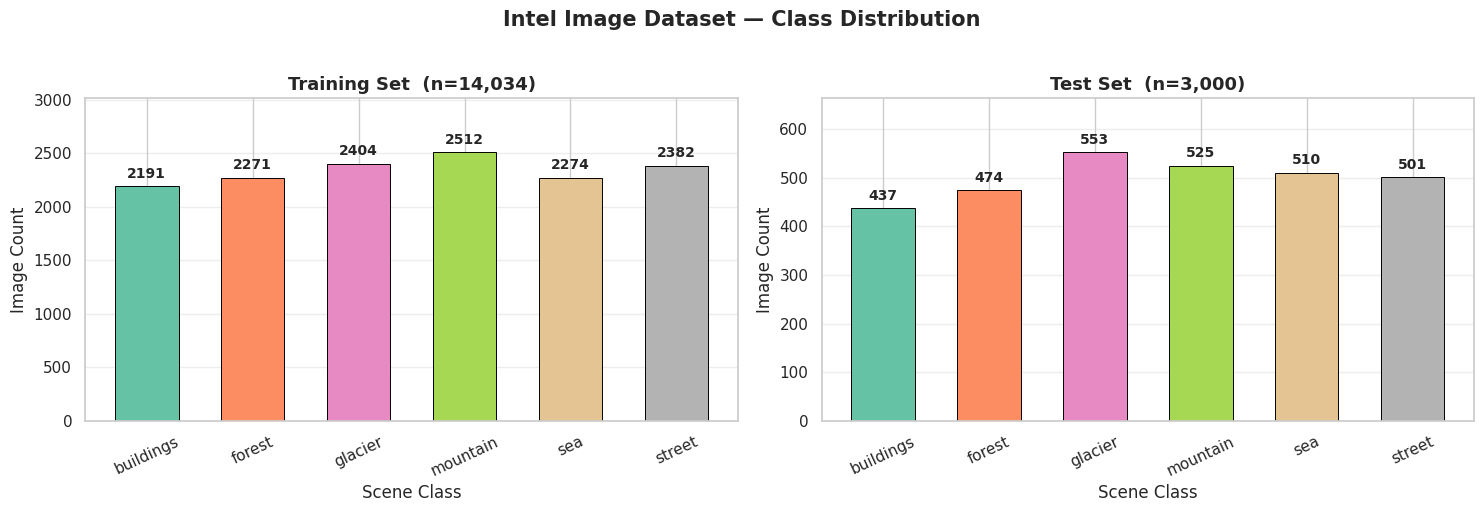

In [ ]:
# ─── Class distribution bar chart ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (counts, title) in zip(axes,
        [(train_counts,"Training Set"),(test_counts,"Test Set")]):
    bars = ax.bar(counts.keys(), counts.values(),
                  color=PALETTE, edgecolor="k", linewidth=0.7, width=0.6)
    ax.bar_label(bars, padding=4, fontsize=10, fontweight="bold")
    ax.set_title(f"{title}  (n={sum(counts.values()):,})",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Scene Class"); ax.set_ylabel("Image Count")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, max(counts.values())*1.20)
    ax.grid(axis="y", alpha=0.35)
plt.suptitle("Intel Image Dataset — Class Distribution",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("eda_class_dist.png", dpi=150, bbox_inches="tight"); plt.show()


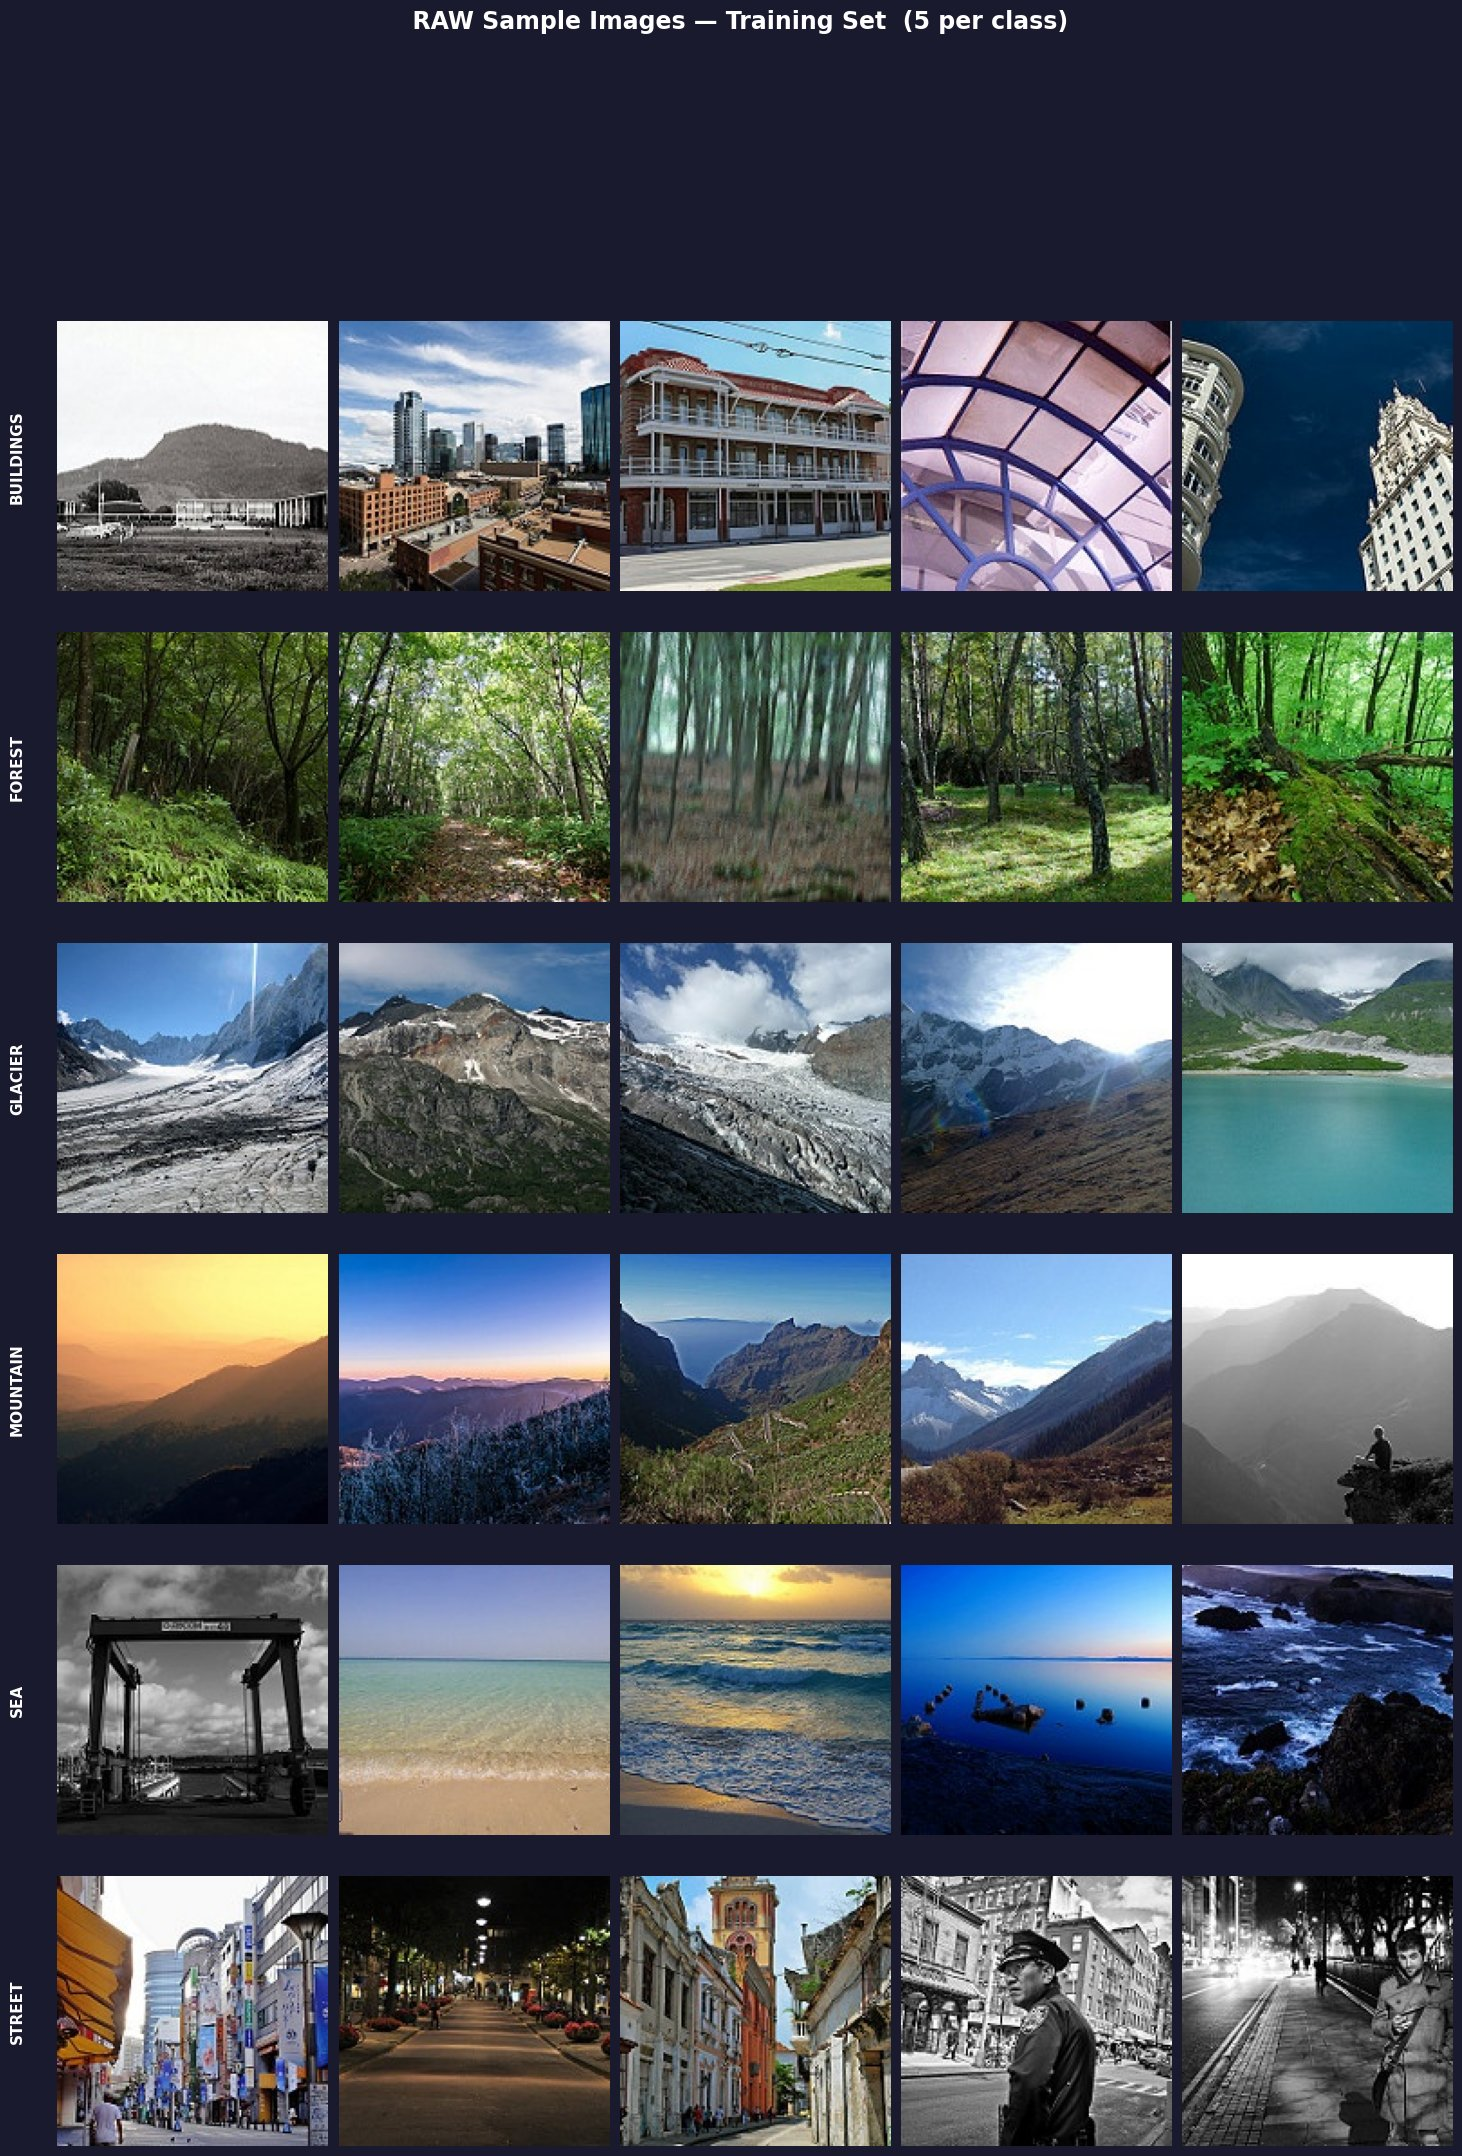

  Raw sample grid saved → raw_samples.png


In [ ]:
# ─── RAW sample images — 5 per class ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 24))
fig.patch.set_facecolor("#1a1a2e")
fig.suptitle("  RAW Sample Images — Training Set  (5 per class)",
             fontsize=17, fontweight="bold", color="white", y=1.005)
gs = gridspec.GridSpec(6, 5, figure=fig, hspace=0.06, wspace=0.04)

CLASS_COLORS = ["#e74c3c","#27ae60","#2980b9","#8e44ad","#f39c12","#16a085"]
for row, cls in enumerate(CFG["CLASSES"]):
    paths = sorted((CFG["TRAIN_DIR"]/cls).glob("*.jpg"))[:5]
    for col, p in enumerate(paths):
        ax = fig.add_subplot(gs[row, col])
        img = np.array(Image.open(p).convert("RGB"))
        ax.imshow(img); ax.axis("off")
        for spine in ax.spines.values():
            spine.set_edgecolor(CLASS_COLORS[row]); spine.set_linewidth(3)
        if col == 0:
            ax.text(-0.12, 0.5, cls.upper(), transform=ax.transAxes,
                    fontsize=11, fontweight="bold", color="white", va="center",
                    ha="right", rotation=90)
plt.savefig("raw_samples.png", dpi=120, bbox_inches="tight"); plt.show()
print("  Raw sample grid saved → raw_samples.png")


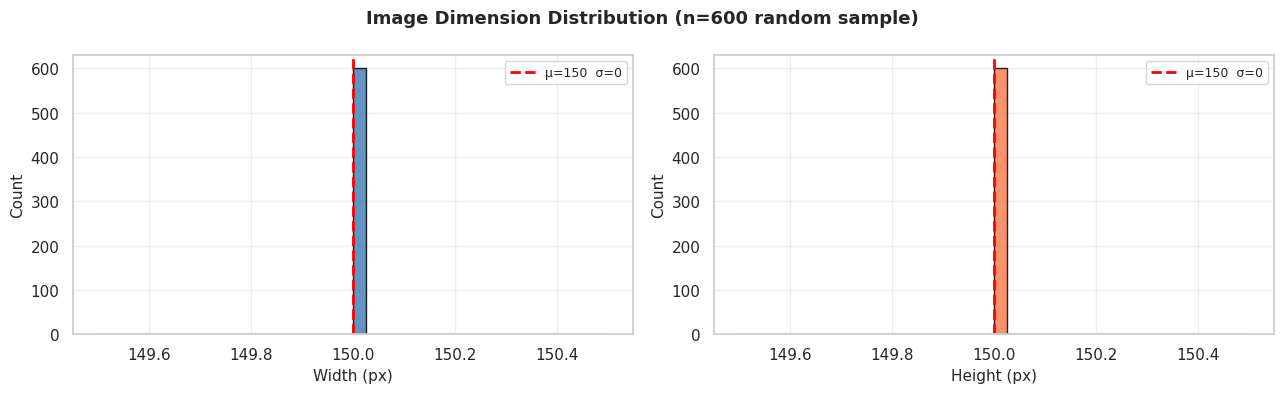

Width  μ=150 min=150 max=150
Height μ=150 min=150 max=150


In [ ]:
# ─── Image dimension distribution ────────────────────────────────────────────
all_paths = list(CFG["TRAIN_DIR"].rglob("*.jpg"))
sample    = random.sample(all_paths, min(600, len(all_paths)))
widths, heights = [], []
for p in sample:
    with Image.open(p) as im:
        w,h = im.size; widths.append(w); heights.append(h)

fig, axes = plt.subplots(1,2, figsize=(13,4))
for ax,(data,lbl,c) in zip(axes,[
    (widths,"Width (px)","steelblue"),(heights,"Height (px)","coral")]):
    ax.hist(data, bins=40, color=c, edgecolor="k", alpha=0.85)
    ax.axvline(np.mean(data), color="red", ls="--", lw=2,
               label=f"μ={np.mean(data):.0f}  σ={np.std(data):.0f}")
    ax.set_xlabel(lbl,fontsize=11); ax.set_ylabel("Count",fontsize=11)
    ax.legend(fontsize=9); ax.grid(alpha=0.35)
plt.suptitle("Image Dimension Distribution (n=600 random sample)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("eda_dims.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Width  μ={np.mean(widths):.0f} min={min(widths)} max={max(widths)}")
print(f"Height μ={np.mean(heights):.0f} min={min(heights)} max={max(heights)}")


Computing per-class RGB means … done


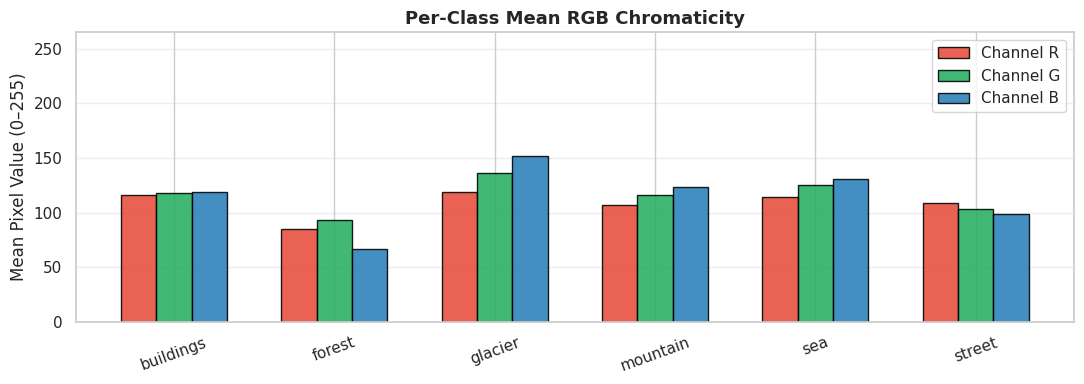

In [ ]:
# ─── Per-class mean RGB chromaticity ─────────────────────────────────────────
print("Computing per-class RGB means … ", end="", flush=True)
class_rgb = {}
for cls in CFG["CLASSES"]:
    imgs = sorted((CFG["TRAIN_DIR"]/cls).glob("*.jpg"))[:100]
    arr  = np.stack([np.array(Image.open(p).convert("RGB")
                    .resize((64,64)), dtype=np.float32) for p in imgs])
    class_rgb[cls] = arr.mean(axis=(0,1,2))
print("done")

fig, ax = plt.subplots(figsize=(11,4))
x = np.arange(len(CFG["CLASSES"])); w = 0.22
for i,(ch,col) in enumerate(zip(["R","G","B"],["#e74c3c","#27ae60","#2980b9"])):
    vals = [class_rgb[c][i] for c in CFG["CLASSES"]]
    ax.bar(x+(i-1)*w, vals, w, label=f"Channel {ch}", color=col, alpha=0.88, edgecolor="k")
ax.set_xticks(x); ax.set_xticklabels(CFG["CLASSES"], rotation=20)
ax.set_ylabel("Mean Pixel Value (0–255)"); ax.set_ylim(0,265)
ax.set_title("Per-Class Mean RGB Chromaticity", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.35)
plt.tight_layout()
plt.savefig("eda_rgb.png", dpi=150, bbox_inches="tight"); plt.show()


---
## 2️⃣ Data Pre-Processing & Input Pipeline

### 2.1 Stratified Train / Val Split
We use `StratifiedShuffleSplit` to preserve class balance in both subsets.


In [ ]:
def gather(root):
    paths, labels = [], []
    for cls in CFG["CLASSES"]:
        for p in sorted((root/cls).glob("*.jpg")):
            paths.append(str(p)); labels.append(CLASS_TO_IDX[cls])
    return np.array(paths), np.array(labels)

all_tr_p, all_tr_l = gather(CFG["TRAIN_DIR"])
test_p,   test_l   = gather(CFG["TEST_DIR"])

sss = StratifiedShuffleSplit(n_splits=1,
                              test_size=CFG["VAL_SPLIT"],
                              random_state=SEED)
tr_idx, val_idx  = next(sss.split(all_tr_p, all_tr_l))
tr_p,  tr_l      = all_tr_p[tr_idx],  all_tr_l[tr_idx]
val_p, val_l     = all_tr_p[val_idx], all_tr_l[val_idx]

print(f"Train : {len(tr_p):,}")
print(f"Val   : {len(val_p):,}")
print(f"Test  : {len(test_p):,}")
print(f"Train label distribution: {dict(sorted(Counter(tr_l).items()))}")


Train : 11,928
Val   : 2,106
Test  : 3,000
Train label distribution: {np.int64(0): 1862, np.int64(1): 1930, np.int64(2): 2043, np.int64(3): 2135, np.int64(4): 1933, np.int64(5): 2025}


### 2.2 Preprocessing & Augmentation Functions

**Training pipeline:**
```
Decode JPEG ➜ Resize 150×150 ➜ RandomFlip H/V ➜ Random Zoom (80–100%)
➜ Colour Jitter (brightness/contrast/saturation/hue) ➜ Random Erasing (Cutout)
➜ Pixel normalise [0,255] → [0,1]   ← pure normalisation, no pretrained mean/std
```
**Val / Test pipeline:**
```
Decode JPEG ➜ Resize 150×150 ➜ Pixel normalise [0,255] → [0,1]
```
> ℹ️ We normalise to [0,1] (not ImageNet mean/std) because the CNN is trained from scratch.


In [ ]:
IMG_SIZE   = CFG["IMG_SIZE"]
AUTOTUNE   = CFG["AUTOTUNE"]
BATCH_SIZE = CFG["BATCH_SIZE"]

# ─── Decode + resize ──────────────────────────────────────────────────────────
@tf.function
def decode_resize(path, label):
    raw   = tf.io.read_file(path)
    img   = tf.image.decode_jpeg(raw, channels=3)
    img   = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img   = tf.cast(img, tf.float32)
    return img, label

# ─── Pixel normalise [0,255] → [0,1] ─────────────────────────────────────────
@tf.function
def normalise(img, label):
    img = img / 255.0
    return img, label

# ─── One-hot encode labels ───────────────────────────────────────────────────
@tf.function
def one_hot_encode(img, label):
    return img, tf.one_hot(label, CFG["NUM_CLASSES"])

# ─── Training augmentation ────────────────────────────────────────────────────
@tf.function
def augment_train(img, label):
    # Flips
    img = tf.image.random_flip_left_right(img, seed=SEED)
    img = tf.image.random_flip_up_down(img, seed=SEED)

    # Random crop → resize  (zoom-in, 80–100 %)
    scale  = tf.random.uniform([], 0.80, 1.00, seed=SEED)
    crop_s = tf.cast(tf.cast(IMG_SIZE, tf.float32) * scale, tf.int32)
    img    = tf.image.random_crop(img, [crop_s, crop_s, 3], seed=SEED)
    img    = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

    # Colour jitter
    img = tf.image.random_brightness(img, 0.25, seed=SEED)
    img = tf.image.random_contrast(img, 0.75, 1.30, seed=SEED)
    img = tf.image.random_saturation(img, 0.70, 1.30, seed=SEED)
    img = tf.image.random_hue(img, 0.08, seed=SEED)
    img = tf.clip_by_value(img, 0.0, 255.0)

    # Random Erasing — erase one 25×25 patch
    ey   = tf.random.uniform([], 15, IMG_SIZE-25, dtype=tf.int32, seed=SEED)
    ex   = tf.random.uniform([], 15, IMG_SIZE-25, dtype=tf.int32, seed=SEED)
    ph   = pw = 25
    y2   = tf.minimum(ey + ph, IMG_SIZE)
    x2   = tf.minimum(ex + pw, IMG_SIZE)
    hole = tf.ones([y2-ey, x2-ex, 3]) * 128.0  # fill with mid-grey
    hole = tf.pad(hole,
                  [[ey, IMG_SIZE-y2],[ex, IMG_SIZE-x2],[0,0]],
                  constant_values=0.0)
    keep_mask = tf.cast(tf.equal(hole, 0.0), tf.float32)
    img  = img * keep_mask + hole * (1.0 - keep_mask)
    return img, label

### 2.3 MixUp & CutMix Augmentations

In [ ]:
# ─── MixUp ────────────────────────────────────────────────────────────────────
def mixup_batch(images, labels, alpha=CFG["MIXUP_ALPHA"]):
    """Blend two samples: x̃ = λx_i + (1-λ)x_j  (applied on normalised images)"""
    batch_size = tf.shape(images)[0]
    # Ensure lam is a Tensor and not a Generator object
    lam = tf.random.uniform(shape=[batch_size], minval=0, maxval=1, dtype=tf.float32, seed=SEED)
    lam = tf.maximum(lam, 1.0 - lam)           # keep λ > 0.5
    lam = lam[:, tf.newaxis, tf.newaxis, tf.newaxis]
    idx = tf.random.shuffle(tf.range(batch_size), seed=SEED)
    mixed_images = lam * images + (1.0-lam) * tf.gather(images, idx)
    lam_1d       = tf.squeeze(lam, [1,2,3])
    # soft labels
    one_hot      = tf.one_hot(labels, CFG["NUM_CLASSES"])
    mixed_labels = (lam_1d[:,tf.newaxis] * one_hot
                    + (1.0-lam_1d)[:,tf.newaxis] * tf.gather(one_hot,idx))
    return mixed_images, mixed_labels

# ─── CutMix ───────────────────────────────────────────────────────────────────
def cutmix_batch(images, labels, alpha=CFG["CUTMIX_ALPHA"]):
    """Paste a rectangular region from one image into another."""
    batch_size = tf.shape(images)[0]
    lam = tf.random.uniform([], 0.0, 1.0, seed=SEED)
    cut_rat  = tf.sqrt(1.0 - lam)
    cut_w    = tf.cast(IMG_SIZE * cut_rat, tf.int32)
    cut_h    = tf.cast(IMG_SIZE * cut_rat, tf.int32)
    cx = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32, seed=SEED)
    cy = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32, seed=SEED)
    x1 = tf.clip_by_value(cx - cut_w//2, 0, IMG_SIZE)
    y1 = tf.clip_by_value(cy - cut_h//2, 0, IMG_SIZE)
    x2 = tf.clip_by_value(cx + cut_w//2, 0, IMG_SIZE)
    y2 = tf.clip_by_value(cy + cut_h//2, 0, IMG_SIZE)
    # actual lambda after clipping
    lam_adj = 1.0 - tf.cast((x2-x1)*(y2-y1), tf.float32)/float(IMG_SIZE**2)
    idx      = tf.random.shuffle(tf.range(batch_size), seed=SEED)
    imgs_b   = tf.gather(images, idx)
    # build mask
    mask = tf.pad(tf.ones([y2-y1, x2-x1, 3]),
                  [[y1, IMG_SIZE-y2],[x1, IMG_SIZE-x2],[0,0]])
    mixed    = images*(1.0-mask) + imgs_b*mask
    one_hot  = tf.one_hot(labels, CFG["NUM_CLASSES"])
    mixed_lbl= lam_adj*one_hot + (1.0-lam_adj)*tf.gather(one_hot, idx)
    return mixed, mixed_lbl

# ─── Apply MixUp or CutMix randomly at batch level ────────────────────────────
@tf.function
def apply_mixup_cutmix(images, labels):
    choice = tf.random.uniform([], seed=SEED)
    images_norm = images / 255.0   # normalise before mixing
    mixed_img, mixed_lbl = tf.cond(
        choice < 0.5,
        lambda: mixup_batch(images_norm, labels),
        lambda: cutmix_batch(images_norm, labels)
    )
    return mixed_img, mixed_lbl


### 2.4 Build tf.data Pipelines

In [ ]:
# ─── Training dataset ─────────────────────────────────────────────────────────
def make_train_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize,   num_parallel_calls=AUTOTUNE)
    ds = ds.map(augment_train,   num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.map(apply_mixup_cutmix, num_parallel_calls=AUTOTUNE)   # MixUp/CutMix
    ds = ds.prefetch(AUTOTUNE)
    return ds

# ─── Val / Test dataset (no augmentation) ────────────────────────────────────
def make_eval_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.map(normalise,     num_parallel_calls=AUTOTUNE)
    ds = ds.map(one_hot_encode, num_parallel_calls=AUTOTUNE) # Added one-hot encoding here
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_train_dataset(tr_p, tr_l)
val_ds   = make_eval_dataset(val_p, val_l)
test_ds  = make_eval_dataset(test_p, test_l)

STEPS_PER_EPOCH = len(tr_p) // BATCH_SIZE
print(f"Steps/epoch : {STEPS_PER_EPOCH}")
print(f"Train batches: {len(train_ds)}")
print(f"Val   batches: {len(val_ds)}")
print(f"Test  batches: {len(test_ds)}")

I0000 00:00:1773799581.139354      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1773799581.142408      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Steps/epoch : 93
Train batches: 93
Val   batches: 17
Test  batches: 24


### 2.5 Visualise Preprocessed & Augmented Samples

In [ ]:
# ─── Pull one batch from training pipeline ────────────────────────────────────
sample_images, sample_labels = next(iter(train_ds))
sample_images_np = sample_images.numpy()
sample_labels_np = sample_labels.numpy()

print(f"Batch image shape : {sample_images_np.shape}")
print(f"Batch label shape : {sample_labels_np.shape}  (soft labels from MixUp/CutMix)")
print(f"Pixel range       : [{sample_images_np.min():.3f}, {sample_images_np.max():.3f}]")
print(f"Pixel mean        : {sample_images_np.mean():.4f}")
print(f"Pixel std         : {sample_images_np.std():.4f}")


2026-03-18 02:06:24.571678: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Batch image shape : (128, 150, 150, 3)
Batch label shape : (128, 6)  (soft labels from MixUp/CutMix)
Pixel range       : [0.000, 1.000]
Pixel mean        : 0.4291
Pixel std         : 0.2258


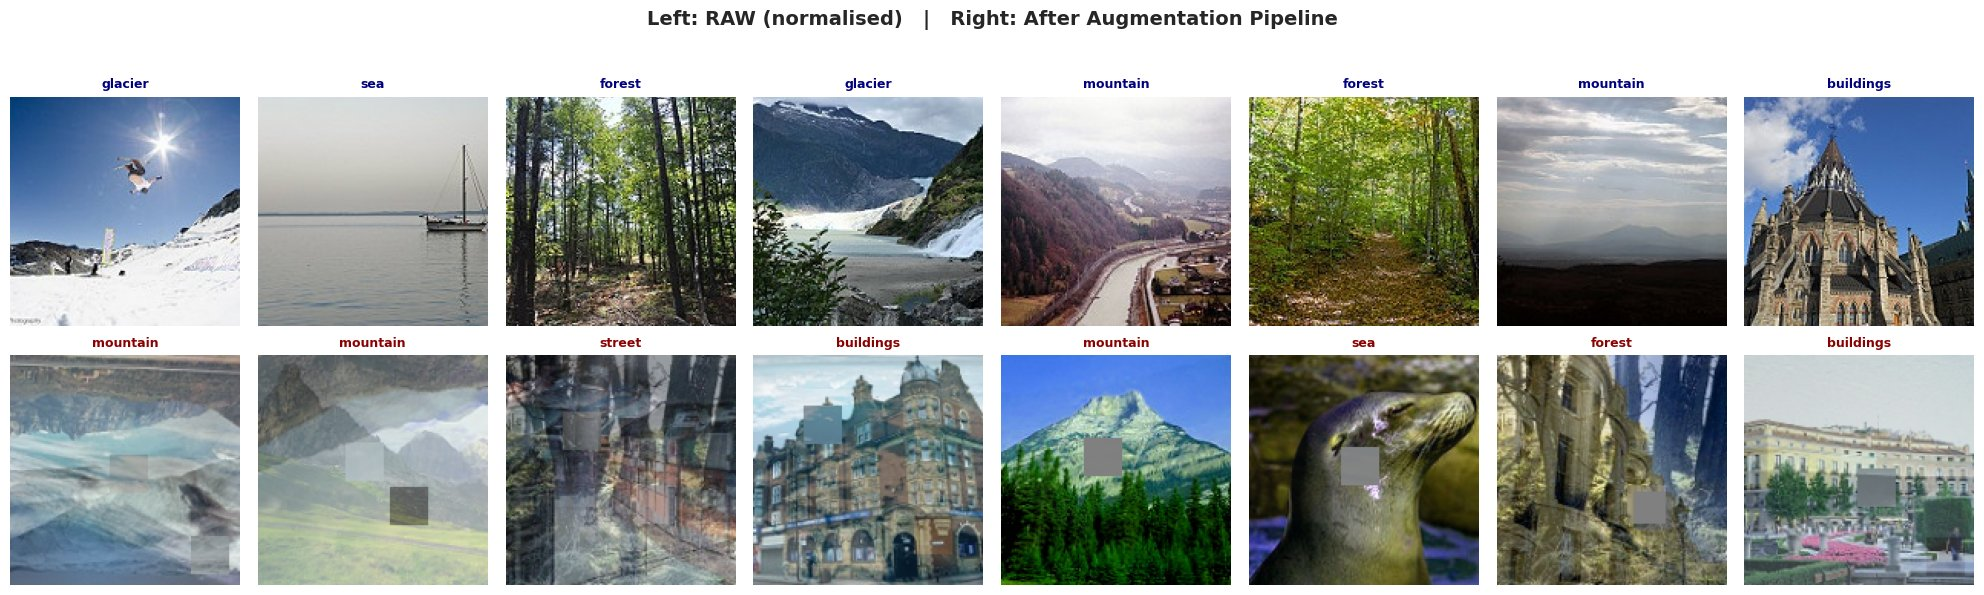

  Saved → raw_vs_augmented.png


In [ ]:
# ─── Side-by-side: RAW vs PREPROCESSED (augmented) for 8 samples ─────────────
n_show   = 8
raw_imgs = []   # load the same images without augmentation for comparison
raw_lbls = []

for i in range(n_show):
    p = tr_p[i]
    img_raw = np.array(Image.open(p).convert("RGB").resize((IMG_SIZE,IMG_SIZE)),
                       dtype=np.float32)
    raw_imgs.append(img_raw / 255.0)
    raw_lbls.append(tr_l[i])

fig, axes = plt.subplots(2, n_show, figsize=(20, 6))
fig.suptitle("Left: RAW (normalised)   |   Right: After Augmentation Pipeline",
             fontsize=14, fontweight="bold", y=1.02)

for col in range(n_show):
    # Row 0 — raw
    ax = axes[0, col]
    ax.imshow(np.clip(raw_imgs[col], 0, 1))
    ax.set_title(IDX_TO_CLASS[raw_lbls[col]], fontsize=9, fontweight="bold", color="navy")
    ax.axis("off")
    ax.set_xlabel("RAW", fontsize=8)

    # Row 1 — augmented (from batch)
    ax2 = axes[1, col]
    aug_img = np.clip(sample_images_np[col], 0, 1)
    # argmax of soft label
    aug_cls = CFG["CLASSES"][np.argmax(sample_labels_np[col])]
    ax2.imshow(aug_img)
    ax2.set_title(f"{aug_cls}", fontsize=9, fontweight="bold", color="darkred")
    ax2.axis("off")
    ax2.set_xlabel("AUGMENTED", fontsize=8)

    # Draw connecting arrow
    for axx in [ax, ax2]:
        for spine in axx.spines.values():
            spine.set_visible(True); spine.set_linewidth(1.5)
            spine.set_edgecolor("#95a5a6")

plt.tight_layout()
plt.savefig("raw_vs_augmented.png", dpi=130, bbox_inches="tight")
plt.show()
print("  Saved → raw_vs_augmented.png")


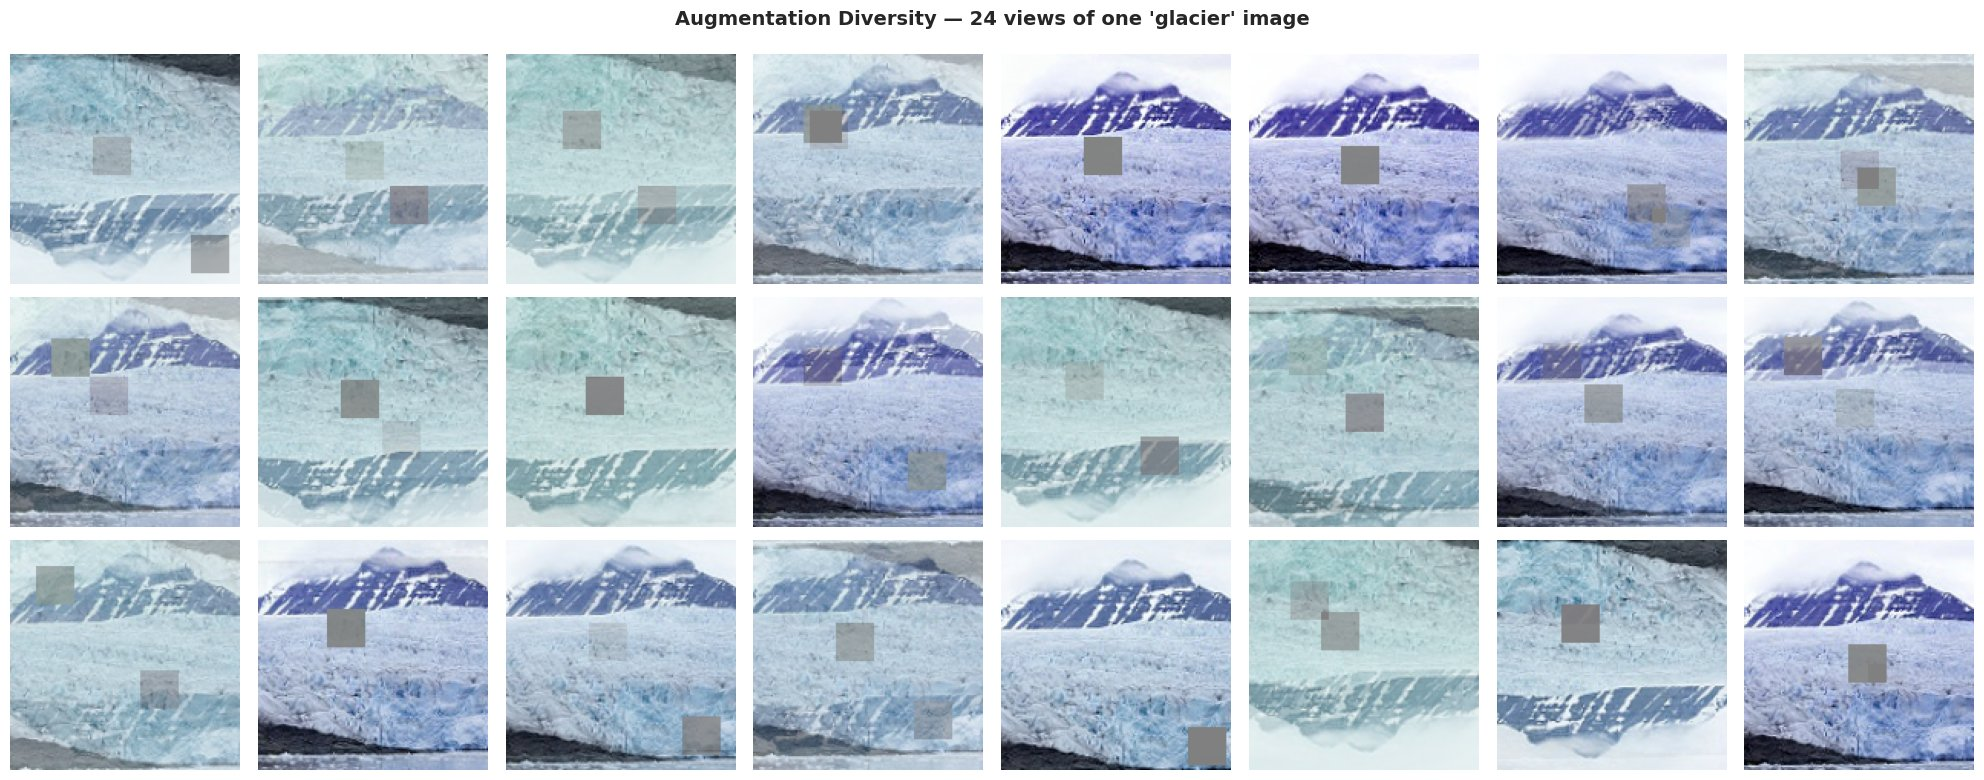

  Saved → augmentation_diversity.png


In [ ]:
# ─── Augmentation variety grid — same image, 12 different augmentations ────────
one_path  = tr_p[42]
one_label = tr_l[42]

one_ds = (tf.data.Dataset
          .from_tensor_slices(([one_path]*48, [one_label]*48))
          .map(decode_resize, num_parallel_calls=AUTOTUNE)
          .map(augment_train, num_parallel_calls=AUTOTUNE)
          .batch(48)
          .map(apply_mixup_cutmix))
aug_batch, _ = next(iter(one_ds))
aug_batch_np = aug_batch.numpy()

fig, axes = plt.subplots(3, 8, figsize=(20, 8))
fig.suptitle(f"Augmentation Diversity — 24 views of one '{IDX_TO_CLASS[one_label]}' image",
             fontsize=14, fontweight="bold")
for i, ax in enumerate(axes.flatten()):
    ax.imshow(np.clip(aug_batch_np[i], 0, 1))
    ax.axis("off")
plt.tight_layout()
plt.savefig("augmentation_diversity.png", dpi=120, bbox_inches="tight")
plt.show()
print("  Saved → augmentation_diversity.png")


---
## 3️⃣ Model Design in Keras
### 3.1 Custom Deep CNN Architecture

**Architecture Overview (DeepSceneNet):**

```
Input 150×150×3
│
├─ StemBlock:  Conv 3×3/32 → BN → ReLU → Conv 3×3/32 → BN → ReLU → MaxPool 2×2
│              (150→75)
│
├─ ResBlock-1: Residual(64)  × 2   + MaxPool  (75→37)
├─ ResBlock-2: Residual(128) × 3   + MaxPool  (37→18)
├─ ResBlock-3: Residual(256) × 3   + MaxPool  (18→9)
├─ ResBlock-4: Residual(512) × 2   + MaxPool  (9→4)
│
├─ Channel Attention (SE block) in every residual block
├─ Spatial Attention (CBAM-style) after stage 4
│
├─ GlobalAveragePooling
├─ Dense(512) → BN → ReLU → Dropout(0.5)
├─ Dense(256) → BN → ReLU → Dropout(0.3)
└─ Dense(6, softmax)
```
**Parameters:** 13,144,024 (13,132,184 trainable), all trained from scratch

In [ ]:
# ─── Squeeze-and-Excitation (Channel Attention) block ────────────────────────
def se_block(x, reduction=16):
    """Recalibrate channel-wise feature responses."""
    c     = x.shape[-1]
    # Squeeze
    se    = layers.GlobalAveragePooling2D()(x)
    # Excite
    se    = layers.Dense(c // reduction, activation="relu",
                         kernel_initializer="he_normal")(se)
    se    = layers.Dense(c, activation="sigmoid",
                         kernel_initializer="he_normal")(se)
    se    = layers.Reshape((1, 1, c))(se)
    return layers.Multiply()([x, se])

# ─── Residual block with optional projection shortcut ─────────────────────────
def residual_block(x, filters, stride=1, l2=CFG["L2_REG"]):
    """Pre-activation residual block with SE attention."""
    shortcut = x
    # Projection shortcut if dimensions change
    if x.shape[-1] != filters or stride != 1:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same",
                                 use_bias=False,
                                 kernel_regularizer=regularizers.l2(l2))(x)
        shortcut = layers.BatchNormalization()(shortcut)

    # Main path
    out = layers.BatchNormalization()(x)
    out = layers.Activation("relu")(out)
    out = layers.Conv2D(filters, 3, strides=stride, padding="same",
                        use_bias=False,
                        kernel_regularizer=regularizers.l2(l2),
                        kernel_initializer="he_normal")(out)

    out = layers.BatchNormalization()(out)
    out = layers.Activation("relu")(out)
    out = layers.Conv2D(filters, 3, padding="same",
                        use_bias=False,
                        kernel_regularizer=regularizers.l2(l2),
                        kernel_initializer="he_normal")(out)

    # Squeeze-and-Excitation
    out = se_block(out, reduction=16)

    return layers.Add()([shortcut, out])

# ─── Spatial Attention block ──────────────────────────────────────────────────
def spatial_attention(x):
    """CBAM-style spatial attention."""
    avg_pool = layers.Lambda(lambda t: K.mean(t, axis=-1, keepdims=True))(x)
    max_pool = layers.Lambda(lambda t: K.max(t,  axis=-1, keepdims=True))(x)
    concat   = layers.Concatenate(axis=-1)([avg_pool, max_pool])
    attn     = layers.Conv2D(1, 7, padding="same", activation="sigmoid",
                              use_bias=False)(concat)
    return layers.Multiply()([x, attn])


In [ ]:
# ─── Build DeepSceneNet ───────────────────────────────────────────────────────
def build_deepscenenet(img_size=IMG_SIZE,
                        num_classes=CFG["NUM_CLASSES"],
                        dropout=CFG["DROPOUT"],
                        l2=CFG["L2_REG"]):
    inp = keras.Input(shape=(img_size, img_size, 3), name="input_image")

    # ── Stem block ────────────────────────────────────────────────────────────
    x = layers.Conv2D(32, 3, padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(l2),
                      kernel_initializer="he_normal", name="stem_conv1")(inp)
    x = layers.BatchNormalization(name="stem_bn1")(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(l2),
                      kernel_initializer="he_normal", name="stem_conv2")(x)
    x = layers.BatchNormalization(name="stem_bn2")(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2, strides=2, name="stem_pool")(x)   # 75×75

    # ── Stage 1: 64 filters × 2 residual blocks ───────────────────────────────
    x = residual_block(x, 64, stride=1)
    x = residual_block(x, 64, stride=1)
    x = layers.MaxPooling2D(2, strides=2, name="pool1")(x)        # 37×37

    # ── Stage 2: 128 filters × 3 residual blocks ──────────────────────────────
    x = residual_block(x, 128, stride=1)
    x = residual_block(x, 128, stride=1)
    x = residual_block(x, 128, stride=1)
    x = layers.MaxPooling2D(2, strides=2, name="pool2")(x)        # 18×18

    # ── Stage 3: 256 filters × 3 residual blocks ──────────────────────────────
    x = residual_block(x, 256, stride=1)
    x = residual_block(x, 256, stride=1)
    x = residual_block(x, 256, stride=1)
    x = layers.MaxPooling2D(2, strides=2, name="pool3")(x)        # 9×9

    # ── Stage 4: 512 filters × 2 residual blocks ──────────────────────────────
    x = residual_block(x, 512, stride=1)
    x = residual_block(x, 512, stride=1)
    x = spatial_attention(x)                                       # CBAM spatial
    x = layers.MaxPooling2D(2, strides=2, name="pool4")(x)        # 4×4

    # ── Global pooling + head ─────────────────────────────────────────────────
    x = layers.GlobalAveragePooling2D(name="gap")(x)

    x = layers.Dense(512, use_bias=False,
                     kernel_regularizer=regularizers.l2(l2),
                     kernel_initializer="he_normal", name="fc1")(x)
    x = layers.BatchNormalization(name="fc1_bn")(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout, name="drop1")(x)

    x = layers.Dense(256, use_bias=False,
                     kernel_regularizer=regularizers.l2(l2),
                     kernel_initializer="he_normal", name="fc2")(x)
    x = layers.BatchNormalization(name="fc2_bn")(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout * 0.6, name="drop2")(x)

    out = layers.Dense(num_classes, activation="softmax",
                       dtype="float32", name="predictions")(x)

    return Model(inputs=inp, outputs=out, name="DeepSceneNet")

model = build_deepscenenet()
model.summary(line_length=90)


Model: "DeepSceneNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃      Param # ┃ Connected to          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer) │ (None, 150, 150, 3)  │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ stem_conv1 (Conv2D)      │ (None, 150, 150, 32) │          864 │ input_image[0][0]     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ stem_bn1                 │ (None, 150, 150, 32) │          128 │ stem_conv1[0][0]      │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation (Activation)  │ (None, 150, 150, 32) │            0 │ stem_bn1[0][0]        │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ stem_conv2 (Conv2D)      │ (None, 150, 150, 32) │        9,216 │ activation[0][0]      │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ stem_bn2                 │ (None, 150, 150, 32) │          128 │ stem_conv2[0][0]      │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation_1             │ (None, 150, 150, 32) │            0 │ stem_bn2[0][0]        │
│ (Activation)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ stem_pool (MaxPooling2D) │ (None, 75, 75, 32)   │            0 │ activation_1[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_1    │ (None, 75, 75, 32)   │          128 │ stem_pool[0][0]       │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation_2             │ (None, 75, 75, 32)   │            0 │ batch_normalization_… │
│ (Activation)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_1 (Conv2D)        │ (None, 75, 75, 64)   │       18,432 │ activation_2[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ batch_normalization_2    │ (None, 75, 75, 64)   │          256 │ conv2d_1[0][0]        │
│ (BatchNormalization)     │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ activation_3             │ (None, 75, 75, 64)   │            0 │ batch_normalization_… │
│ (Activation)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ conv2d_2 (Conv2D)        │ (None, 75, 75, 64)   │       36,864 │ activation_3[0][0]    │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ global_average_pooling2d │ (None, 64)           │            0 │ conv2d_2[0][0]        │
│ (GlobalAveragePooling2D) │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dense (Dense)            │ (None, 4)            │          260 │ global_average_pooli… │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dense_1 (Dense)          │ (None, 64)           │          320 │ dense[0][0]         

 Total params: 13,144,024 (50.14 MB)

 Trainable params: 13,132,184 (50.10 MB)

 Non-trainable params: 11,840 (46.25 KB)

In [ ]:
# ─── Parameter count ─────────────────────────────────────────────────────────
total_params     = model.count_params()
trainable_params = sum(K.count_params(w) for w in model.trainable_weights)
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Non-trainable        : {total_params - trainable_params:,}")


Total parameters     : 13,144,024
Trainable parameters : 13,132,184
Non-trainable        : 11,840




In [ ]:
# ─── Architecture diagram (text-based) ───────────────────────────────────────
keras.utils.plot_model(model,
                        to_file="model_architecture.png",
                        show_shapes=True,
                        show_layer_names=True,
                        expand_nested=False,
                        dpi=100)
from IPython.display import Image as IPImage
IPImage("model_architecture.png", width=700)


---
## 4️⃣ Model Training
### 4.1 Custom Learning-Rate Schedule (Cosine Annealing with Warmup)

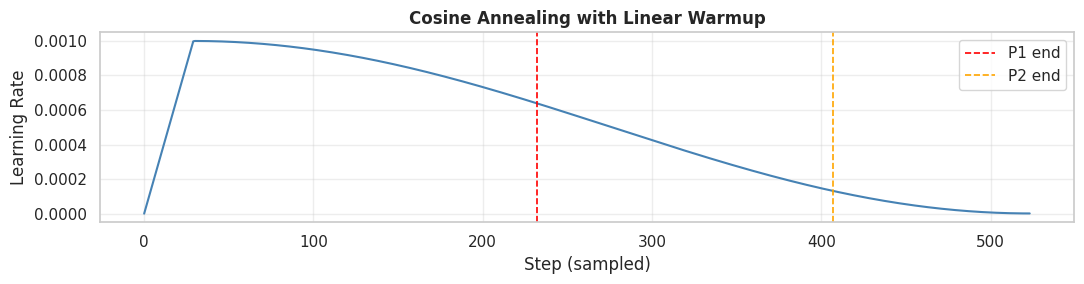

In [ ]:
class CosineAnnealingWarmup(keras.optimizers.schedules.LearningRateSchedule):
    """Linear warmup for `warmup_steps`, then cosine annealing to `min_lr`."""
    def __init__(self, base_lr, total_steps, warmup_steps, min_lr=1e-6):
        super().__init__()
        self.base_lr      = base_lr
        self.total_steps  = total_steps
        self.warmup_steps = warmup_steps
        self.min_lr       = min_lr

    def __call__(self, step):
        step        = tf.cast(step, tf.float32)
        warmup_lr   = self.base_lr * (step / float(self.warmup_steps))
        cos_factor  = 0.5 * (1.0 + tf.cos(
            np.pi * (step - self.warmup_steps) /
            float(self.total_steps - self.warmup_steps)
        ))
        cosine_lr   = self.min_lr + (self.base_lr - self.min_lr) * cos_factor
        return tf.where(step < self.warmup_steps, warmup_lr, cosine_lr)

    def get_config(self):
        return dict(base_lr=self.base_lr, total_steps=self.total_steps,
                    warmup_steps=self.warmup_steps, min_lr=self.min_lr)

# ─── Visualise schedule ───────────────────────────────────────────────────────
total_steps   = STEPS_PER_EPOCH * (CFG["EPOCHS_P1"]+CFG["EPOCHS_P2"]+CFG["EPOCHS_P3"])
warmup_steps  = STEPS_PER_EPOCH * CFG["WARMUP_EPOCHS"]
sched_preview = CosineAnnealingWarmup(1e-3, total_steps, warmup_steps)
xs            = np.arange(total_steps)
ys            = [float(sched_preview(x)) for x in xs[::max(1,total_steps//500)]]

fig, ax = plt.subplots(figsize=(11,3))
ax.plot(ys, color="steelblue", lw=1.5)
ax.axvline(len(ys)*STEPS_PER_EPOCH*CFG["EPOCHS_P1"]//total_steps,
           color="red",   ls="--", lw=1.2, label="P1 end")
ax.axvline(len(ys)*STEPS_PER_EPOCH*(CFG["EPOCHS_P1"]+CFG["EPOCHS_P2"])//total_steps,
           color="orange",ls="--", lw=1.2, label="P2 end")
ax.set_xlabel("Step (sampled)"); ax.set_ylabel("Learning Rate")
ax.set_title("Cosine Annealing with Linear Warmup", fontsize=12, fontweight="bold")
ax.legend(); ax.grid(alpha=0.35)
plt.tight_layout()
plt.savefig("lr_schedule.png", dpi=150, bbox_inches="tight"); plt.show()


### 4.2 Loss Function: Label-Smoothed Categorical Cross-Entropy

In [ ]:
class LabelSmoothingCCE(keras.losses.Loss):
    """Categorical cross-entropy with label smoothing.
    Accepts both hard integer labels and soft one-hot labels.
    """
    def __init__(self, smoothing=CFG["LABEL_SMOOTH"], **kwargs):
        super().__init__(**kwargs)
        self.smoothing = smoothing

    def call(self, y_true, y_pred):
        y_pred   = tf.cast(y_pred, tf.float32)          # ensure float32
        y_pred   = tf.clip_by_value(y_pred, 1e-7, 1.0)
        n_cls    = tf.cast(tf.shape(y_pred)[-1], tf.float32)

        # Handle both sparse (1-D) and one-hot (2-D) y_true
        is_1d = tf.equal(tf.rank(y_true), 1)
        last_dim_mismatch = tf.not_equal(tf.shape(y_true)[-1],
                                          tf.cast(n_cls, tf.int32))
        needs_one_hot = tf.logical_or(is_1d, last_dim_mismatch)
        y_true = tf.cond(
            needs_one_hot,
            lambda: tf.one_hot(tf.cast(y_true, tf.int32),
                               depth=tf.cast(n_cls, tf.int32),
                               dtype=tf.float32),
            lambda: tf.cast(y_true, tf.float32))

        y_smooth = y_true * (1.0 - self.smoothing) + self.smoothing / n_cls
        return -tf.reduce_mean(tf.reduce_sum(y_smooth * tf.math.log(y_pred),
                                              axis=-1))

    def get_config(self):
        cfg = super().get_config()
        cfg["smoothing"] = self.smoothing
        return cfg

print(f"Label smoothing factor : {CFG['LABEL_SMOOTH']}")
loss_fn = LabelSmoothingCCE(smoothing=CFG["LABEL_SMOOTH"])


Label smoothing factor : 0.1


### 4.3 Callbacks

In [ ]:
def get_callbacks(monitor="val_accuracy", mode="max"):
    return [
        callbacks.ModelCheckpoint(
            CFG["CKPT_PATH"],
            monitor=monitor, mode=mode,
            save_best_only=True, verbose=1),

        callbacks.EarlyStopping(
            monitor=monitor, mode=mode,
            patience=12, restore_best_weights=True, verbose=1),

        # Removed ReduceLROnPlateau as it conflicts with LearningRateSchedule
        # callbacks.ReduceLROnPlateau(
        #     monitor="val_loss", factor=0.4,
        #     patience=5, min_lr=1e-7, verbose=1),

        callbacks.TensorBoard(log_dir="./tb_logs", histogram_freq=1),

        callbacks.CSVLogger("training_log.csv", append=True),
    ]

print("Callbacks defined: ModelCheckpoint, EarlyStopping, TensorBoard, CSVLogger")
print("Note: ReduceLROnPlateau is removed as it conflicts with custom LR schedule.")


Callbacks defined: ModelCheckpoint, EarlyStopping, TensorBoard, CSVLogger
Note: ReduceLROnPlateau is removed as it conflicts with custom LR schedule.


### 4.4 Phase 1 — Full Network, High LR with Warmup

In [ ]:
# ─── Phase 1: Build & train from scratch (High LR + Cosine Warmup) ──────────
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

# Re-enable mixed precision after clear_session (policy is global, persists)
tf.keras.mixed_precision.set_global_policy("mixed_float16")

model = build_deepscenenet()

STEPS_PER_EPOCH = len(tr_p) // CFG["BATCH_SIZE"]
IMG_SIZE   = CFG["IMG_SIZE"]
AUTOTUNE   = CFG["AUTOTUNE"]
BATCH_SIZE = CFG["BATCH_SIZE"]

steps_p1    = STEPS_PER_EPOCH * CFG["EPOCHS_P1"]
warmup_p1   = STEPS_PER_EPOCH * CFG["WARMUP_EPOCHS"]
lr_sched_p1 = CosineAnnealingWarmup(CFG["LR_P1"], steps_p1, warmup_p1)

model.compile(
    optimizer=optimizers.Adam(learning_rate=lr_sched_p1),
    loss=loss_fn,
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")]
)

print("=" * 65)
print(f"  PHASE 1 — Training from scratch  "
      f"(max {CFG['EPOCHS_P1']} epochs, LR={CFG['LR_P1']})")
print(f"  Steps/epoch : {STEPS_PER_EPOCH}  |  Batch : {CFG['BATCH_SIZE']}")
print("=" * 65)

history_p1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG["EPOCHS_P1"],
    callbacks=get_callbacks(),
    verbose=1,
)


  PHASE 1 — Training from scratch  (max 40 epochs, LR=0.001)
  Steps/epoch : 93  |  Batch : 128
Epoch 1/40


I0000 00:00:1773799621.595417     133 cuda_dnn.cc:529] Loaded cuDNN version 91002


93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 689ms/step - accuracy: 0.2460 - loss: 4.3445
Epoch 1: val_accuracy improved from -inf to 0.19991, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 105s 803ms/step - accuracy: 0.2468 - loss: 4.3427 - val_accuracy: 0.1999 - val_loss: 4.1770
Epoch 2/40
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 722ms/step - accuracy: 0.4424 - loss: 3.9377
Epoch 2: val_accuracy improved from 0.19991 to 0.36847, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 75s 808ms/step - accuracy: 0.4425 - loss: 3.9373 - val_accuracy: 0.3685 - val_loss: 4.0918
Epoch 3/40
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 744ms/step - accuracy: 0.5050 - loss: 3.7678
Epoch 3: val_accuracy improved from 0.36847 to 0.46914, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 78s 829ms/step - accuracy: 0.5051 - loss: 3.7675 - val_accuracy: 0.4691 - val_loss: 3.6176
Epoch 4/40
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 743ms/step - accuracy: 0.5624 - l

### 4.5 Phase 2 — Lower LR, Harder Convergence

In [ ]:
# ─── Phase 2: Load best weights from P1, lower LR ───────────────────────────
model.load_weights(CFG["CKPT_PATH"])

steps_p2    = STEPS_PER_EPOCH * CFG["EPOCHS_P2"]
lr_sched_p2 = CosineAnnealingWarmup(CFG["LR_P2"], steps_p2, warmup_steps=0)

model.compile(
    optimizer=optimizers.AdamW(learning_rate=lr_sched_p2,
                               weight_decay=CFG["L2_REG"]),
    loss=loss_fn,
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
             keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")]
)

print("=" * 65)
print(f"  PHASE 2 — Lower LR fine-tuning  "
      f"(max {CFG['EPOCHS_P2']} epochs, LR={CFG['LR_P2']})")
print("=" * 65)

history_p2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG["EPOCHS_P2"],
    callbacks=get_callbacks(),
    verbose=1,
)


  PHASE 2 — Lower LR fine-tuning  (max 30 epochs, LR=0.0002)
Epoch 1/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 757ms/step - accuracy: 0.7106 - loss: 2.1027 - top2_acc: 0.8904
Epoch 1: val_accuracy improved from -inf to 0.83191, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 111s 862ms/step - accuracy: 0.7108 - loss: 2.1023 - top2_acc: 0.8905 - val_accuracy: 0.8319 - val_loss: 1.6479 - val_top2_acc: 0.9478
Epoch 2/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 756ms/step - accuracy: 0.7327 - loss: 1.9867 - top2_acc: 0.8948
Epoch 2: val_accuracy did not improve from 0.83191
93/93 ━━━━━━━━━━━━━━━━━━━━ 77s 823ms/step - accuracy: 0.7328 - loss: 1.9864 - top2_acc: 0.8949 - val_accuracy: 0.7749 - val_loss: 1.6433 - val_top2_acc: 0.9198
Epoch 3/30
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.7260 - loss: 1.9069 - top2_acc: 0.8976
Epoch 3: val_accuracy did not improve from 0.83191
93/93 ━━━━━━━━━━━━━━━━━━━━ 77s 821ms/step - accuracy: 0.7261 - loss: 1.9067 - top2_acc: 0.8976 

### 4.6 Phase 3 — Final Fine Convergence

In [ ]:
# ─── Phase 3: Load best P2 weights, final fine convergence ──────────────────
model.load_weights(CFG["CKPT_PATH"])

steps_p3    = STEPS_PER_EPOCH * CFG["EPOCHS_P3"]
lr_sched_p3 = CosineAnnealingWarmup(CFG["LR_P3"], steps_p3, warmup_steps=0)

model.compile(
    optimizer=optimizers.AdamW(learning_rate=lr_sched_p3,
                               weight_decay=CFG["L2_REG"]),
    loss=loss_fn,
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
             keras.metrics.TopKCategoricalAccuracy(k=2, name="top2_acc")]
)

print("=" * 65)
print(f"  PHASE 3 — Final convergence  "
      f"(max {CFG['EPOCHS_P3']} epochs, LR={CFG['LR_P3']})")
print("=" * 65)

history_p3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CFG["EPOCHS_P3"],
    callbacks=get_callbacks(),
    verbose=1,
)


  PHASE 3 — Final convergence  (max 20 epochs, LR=5e-05)
Epoch 1/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.7921 - loss: 1.4350 - top2_acc: 0.9385
Epoch 1: val_accuracy improved from -inf to 0.89791, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 108s 861ms/step - accuracy: 0.7922 - loss: 1.4349 - top2_acc: 0.9385 - val_accuracy: 0.8979 - val_loss: 1.0630 - val_top2_acc: 0.9739
Epoch 2/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.7963 - loss: 1.4304 - top2_acc: 0.9382
Epoch 2: val_accuracy did not improve from 0.89791
93/93 ━━━━━━━━━━━━━━━━━━━━ 77s 821ms/step - accuracy: 0.7964 - loss: 1.4304 - top2_acc: 0.9382 - val_accuracy: 0.8955 - val_loss: 1.0611 - val_top2_acc: 0.9744
Epoch 3/20
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - accuracy: 0.8015 - loss: 1.4299 - top2_acc: 0.9398
Epoch 3: val_accuracy improved from 0.89791 to 0.90598, saving model to /kaggle/working/best_cnn_model.keras
93/93 ━━━━━━━━━━━━━━━━━━━━ 78s 838ms/step

### 4.7 Training Curves

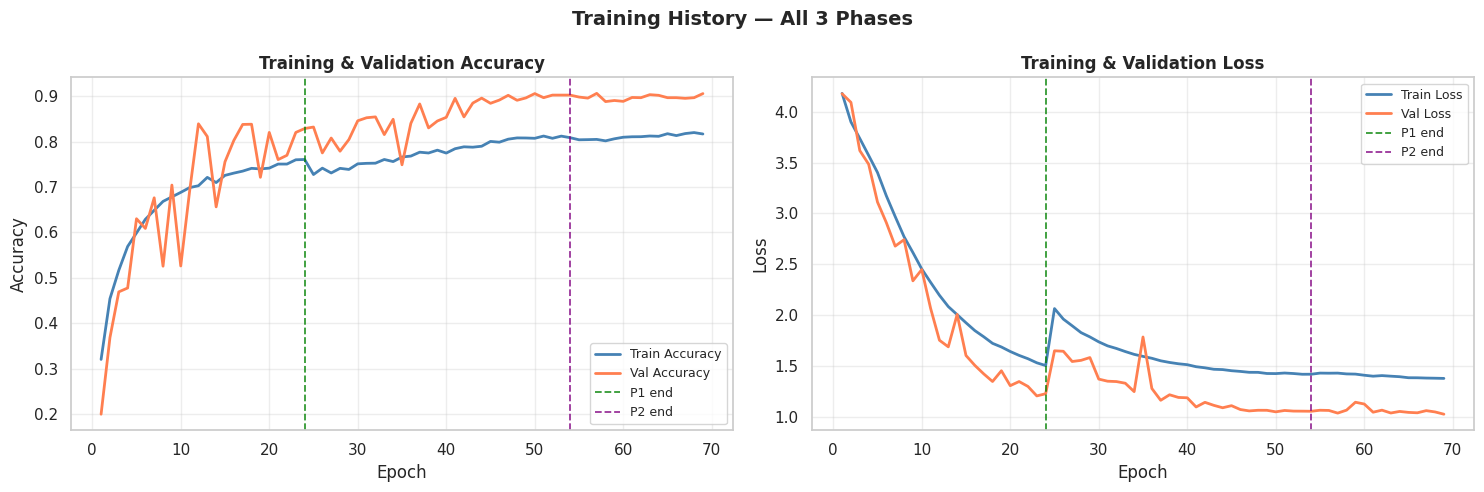

Best Val Accuracy : 0.9060
Best Val Loss     : 1.0240


In [ ]:
# ─── Concatenate all phase histories ─────────────────────────────────────────
def concat_hist(h1, h2, h3, key):
    return h1.history.get(key,[]) + h2.history.get(key,[]) + h3.history.get(key,[])

tr_acc  = concat_hist(history_p1, history_p2, history_p3, "accuracy")
val_acc = concat_hist(history_p1, history_p2, history_p3, "val_accuracy")
tr_loss = concat_hist(history_p1, history_p2, history_p3, "loss")
val_loss= concat_hist(history_p1, history_p2, history_p3, "val_loss")

epochs_all   = range(1, len(tr_acc)+1)
p1_end = len(history_p1.history["accuracy"])
p2_end = p1_end + len(history_p2.history["accuracy"])

fig, axes = plt.subplots(1,2, figsize=(15,5))
for ax,(tr,va,lbl) in zip(axes,[
        (tr_acc,  val_acc,  "Accuracy"),
        (tr_loss, val_loss, "Loss")]):
    ax.plot(epochs_all, tr, lw=2, label=f"Train {lbl}", color="steelblue")
    ax.plot(epochs_all, va, lw=2, label=f"Val {lbl}",   color="coral")
    ax.axvline(p1_end, color="green",  ls="--", lw=1.3, alpha=0.8, label="P1 end")
    ax.axvline(p2_end, color="purple", ls="--", lw=1.3, alpha=0.8, label="P2 end")
    ax.set_xlabel("Epoch"); ax.set_ylabel(lbl)
    ax.set_title(f"Training & Validation {lbl}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=9); ax.grid(alpha=0.35)

plt.suptitle("Training History — All 3 Phases", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Best Val Accuracy : {max(val_acc):.4f}")
print(f"Best Val Loss     : {min(val_loss):.4f}")


> **Interpretation.** Phase 1 (high learning rate with warmup) reached 83.9 % validation accuracy at epoch 12 before early stopping at epoch 24. Phase 2 lifted it to **90.55 %** (epoch 26), and Phase 3 added only a marginal gain to a best of **90.60 %**, showing the model had converged. Training accuracy stays below validation accuracy throughout because MixUp, CutMix and label smoothing make the training batches deliberately harder, not because of underfitting.

---
## 5️⃣ Model Evaluation & Error Analysis

### 5.1 Standard Evaluation (No TTA)

In [ ]:
model.load_weights(CFG["CKPT_PATH"])

# ─── Get predictions on test set ──────────────────────────────────────────────
print("Evaluating on test set …")
eval_results = model.evaluate(test_ds, verbose=0)
test_loss, test_acc = eval_results[0], eval_results[1]
test_top2 = eval_results[2] if len(eval_results) > 2 else None

print(f"\n{'='*55}")
print(f"  Test Loss          : {test_loss:.4f}")
print(f"  Test Accuracy      : {test_acc:.4f}  ({test_acc*100:.2f} %)")
if test_top2 is not None:
    print(f"  Test Top-2 Accuracy: {test_top2:.4f}  ({test_top2*100:.2f} %)")
print(f"{'='*55}")


Evaluating on test set …

  Test Loss          : 1.0602
  Test Accuracy      : 0.8903  (89.03 %)
  Test Top-2 Accuracy: 0.9737  (97.37 %)


### 5.2 Test-Time Augmentation (TTA)

In [ ]:
print(f"Running TTA with {CFG['TTA_STEPS']} augmented passes …")

# ─── TTA augmentation (lighter than training aug) ─────────────────────────────
@tf.function
def tta_augment(img, label):
    img = tf.image.random_flip_left_right(img, seed=None)
    img = tf.image.random_brightness(img, 0.10)
    img = tf.image.random_contrast(img, 0.90, 1.10)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, label

def make_tta_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.map(normalise,     num_parallel_calls=AUTOTUNE)
    ds = ds.map(tta_augment,   num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

# ─── Accumulate TTA predictions ───────────────────────────────────────────────
tta_preds_acc = None
for step in range(CFG["TTA_STEPS"]):
    tta_ds   = make_tta_dataset(test_p, test_l)
    preds_np = model.predict(tta_ds, verbose=0)
    tta_preds_acc = preds_np if tta_preds_acc is None else tta_preds_acc + preds_np
    if (step+1) % 3 == 0:
        print(f"  TTA step {step+1}/{CFG['TTA_STEPS']}")

tta_preds  = tta_preds_acc / CFG["TTA_STEPS"]
tta_cls    = np.argmax(tta_preds, axis=1)
tta_acc    = np.mean(tta_cls == test_l)

print(f"\n{'='*55}")
print(f"  TTA Test Accuracy  : {tta_acc:.4f}  ({tta_acc*100:.2f} %)")
print(f"  Improvement vs std : +{(tta_acc - test_acc)*100:.2f} pp")
print(f"{'='*55}")


Running TTA with 10 augmented passes …
  TTA step 3/10
  TTA step 6/10
  TTA step 9/10

  TTA Test Accuracy  : 0.8870  (88.70 %)
  Improvement vs std : +-0.33 pp


> **Interpretation.** Test-time augmentation did **not** help: averaging 10 lightly augmented passes gave 88.70 % versus 89.03 % for a single standard pass (-0.33 pp). The flips and colour shifts used for TTA add little information for scene images that are already well centred, so the standard prediction is the one reported. The model reaches **97.37 % top-2 accuracy**, meaning the correct class is almost always among its two highest-ranked guesses.

### 5.3 Classification Report

In [ ]:
# Full predictions for standard model
pred_probs = model.predict(test_ds, verbose=0)
pred_cls   = np.argmax(pred_probs, axis=1)

print("\n── Classification Report (Standard) " + "─"*30)
print(classification_report(test_l, pred_cls,
                              target_names=CFG["CLASSES"], digits=4))

print("── Classification Report (TTA) " + "─"*34)
print(classification_report(test_l, tta_cls,
                              target_names=CFG["CLASSES"], digits=4))



── Classification Report (Standard) ──────────────────────────────
              precision    recall  f1-score   support

   buildings     0.8925    0.8741    0.8832       437
      forest     0.9610    0.9873    0.9740       474
     glacier     0.8733    0.7975    0.8336       553
    mountain     0.8236    0.8629    0.8428       525
         sea     0.8966    0.9353    0.9155       510
      street     0.9036    0.8982    0.9009       501

    accuracy                         0.8903      3000
   macro avg     0.8918    0.8926    0.8917      3000
weighted avg     0.8903    0.8903    0.8898      3000

── Classification Report (TTA) ──────────────────────────────────
              precision    recall  f1-score   support

   buildings     0.8935    0.8833    0.8884       437
      forest     0.9550    0.9852    0.9699       474
     glacier     0.8637    0.7794    0.8194       553
    mountain     0.8177    0.8629    0.8397       525
         sea     0.8902    0.9216    0.9056       51

### 5.4 Confusion Matrix

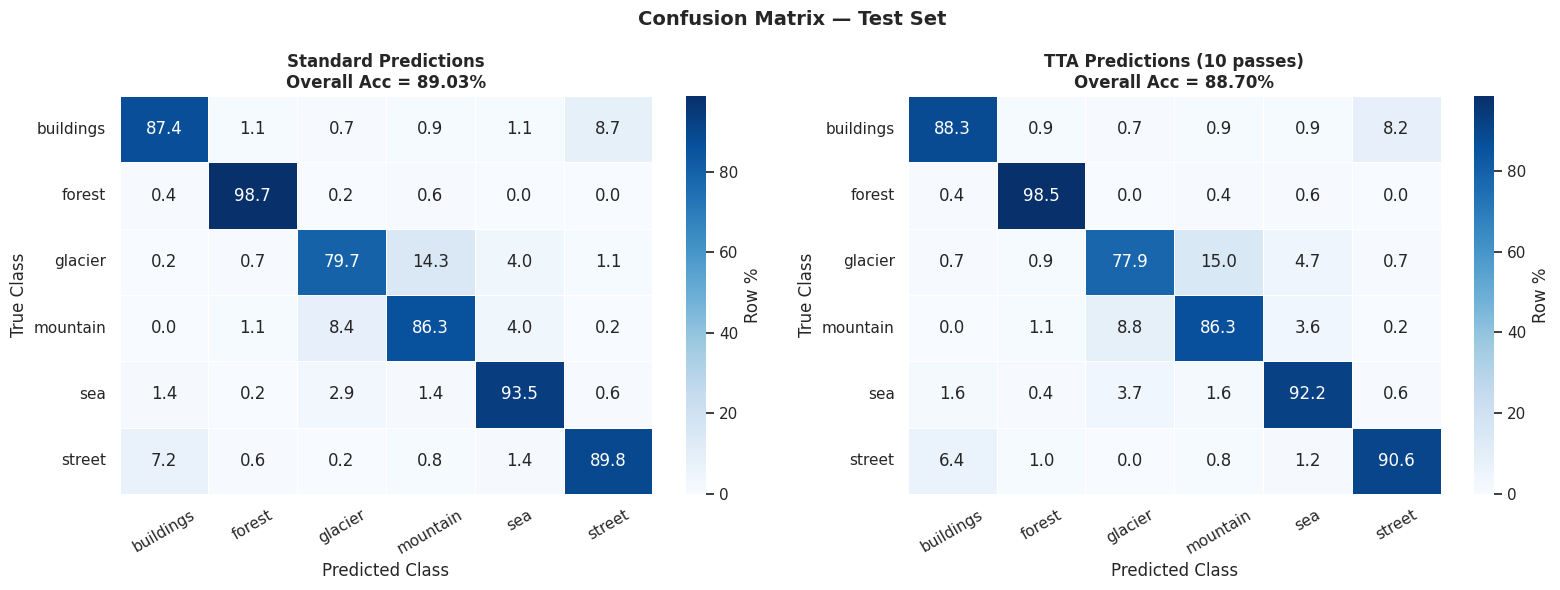

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (preds, title) in zip(axes,[
        (pred_cls, "Standard Predictions"),
        (tta_cls,  f"TTA Predictions ({CFG['TTA_STEPS']} passes)")]):
    cm = confusion_matrix(test_l, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues",
                xticklabels=CFG["CLASSES"],
                yticklabels=CFG["CLASSES"],
                linewidths=0.5, linecolor="white",
                cbar_kws={"label":"Row %"},
                ax=ax)
    ax.set_title(f"{title}\nOverall Acc = {np.trace(cm)/cm.sum()*100:.2f}%",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=30); ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrix — Test Set", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()


### 5.5 ROC Curves (One-vs-Rest)

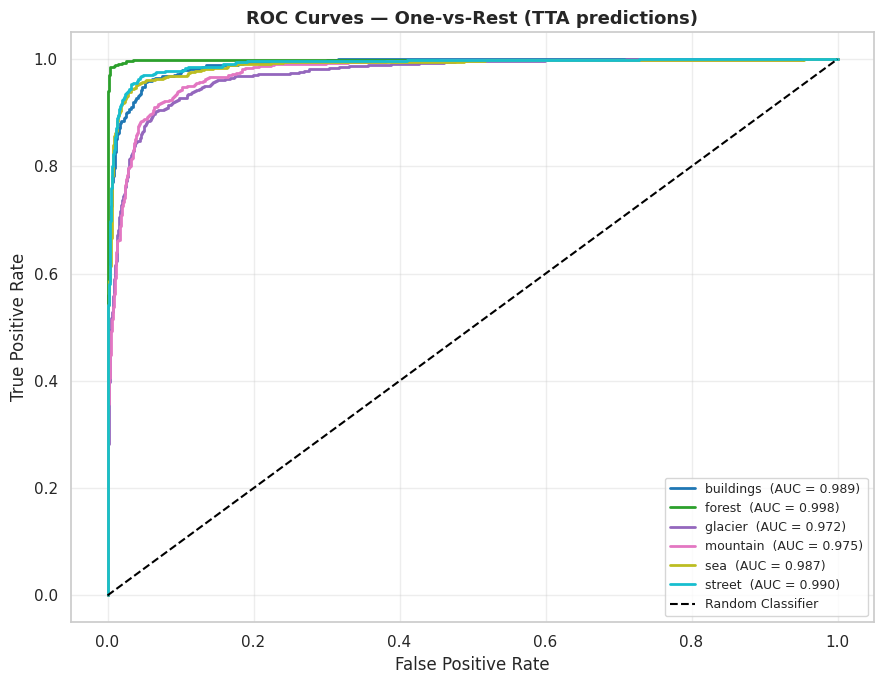

In [ ]:
test_l_bin = label_binarize(test_l, classes=list(range(CFG["NUM_CLASSES"])))

fig, ax = plt.subplots(figsize=(9, 7))
colors  = plt.cm.tab10(np.linspace(0, 1, CFG["NUM_CLASSES"]))

for i, (cls, col) in enumerate(zip(CFG["CLASSES"], colors)):
    fpr, tpr, _ = roc_curve(test_l_bin[:, i], tta_preds[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, color=col, label=f"{cls}  (AUC = {roc_auc:.3f})")

ax.plot([0,1],[0,1],"k--",lw=1.5, label="Random Classifier")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate",  fontsize=12)
ax.set_title("ROC Curves — One-vs-Rest (TTA predictions)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower right"); ax.grid(alpha=0.35)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()


### 5.6 Per-class Precision-Recall Curves

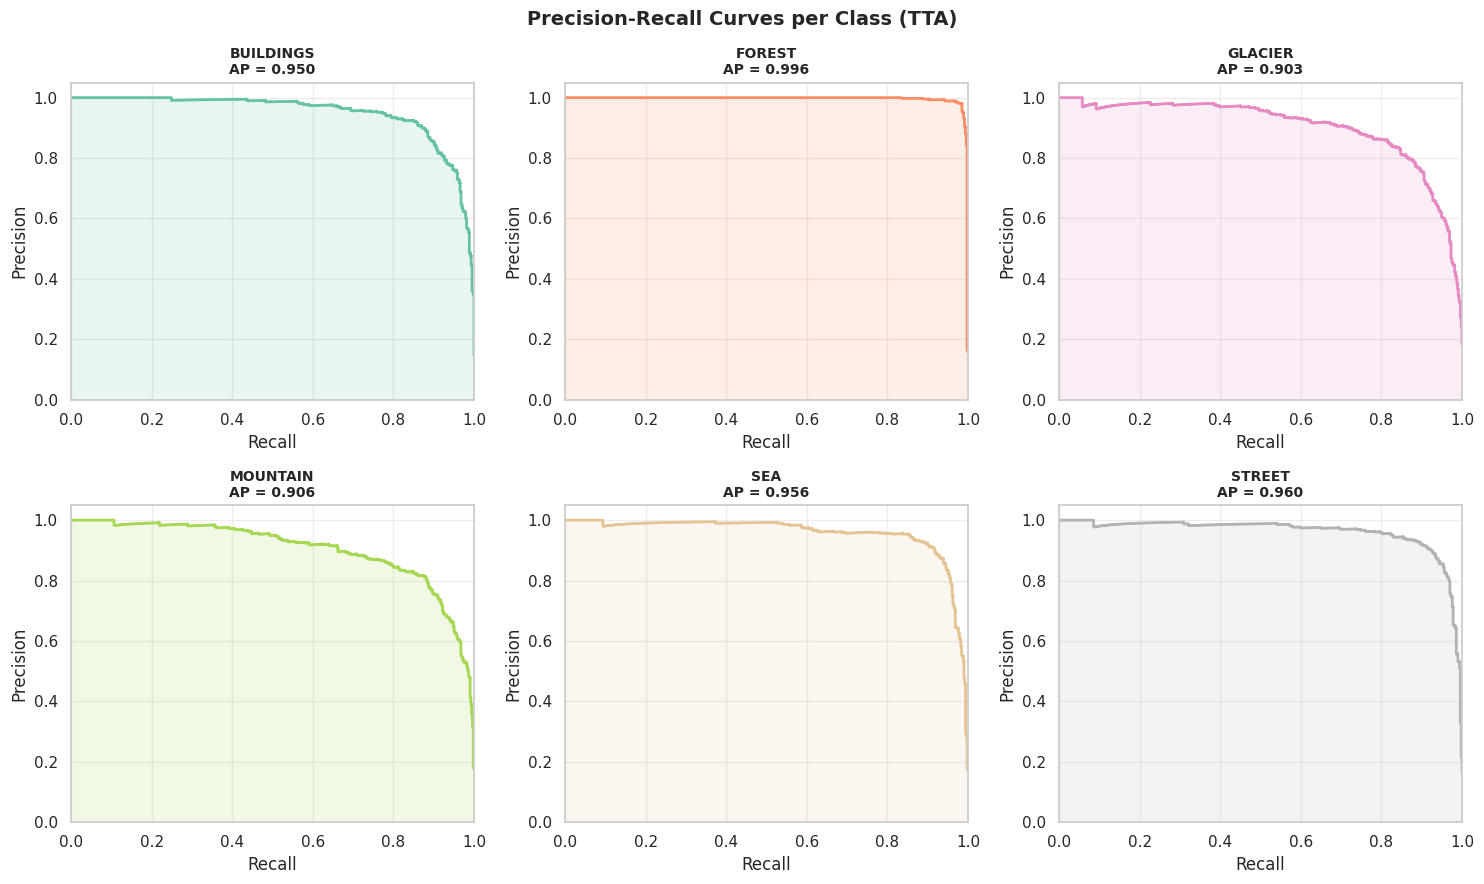

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (i, cls) in zip(axes.flatten(), enumerate(CFG["CLASSES"])):
    prec, rec, _ = precision_recall_curve(test_l_bin[:, i], tta_preds[:, i])
    ap = average_precision_score(test_l_bin[:, i], tta_preds[:, i])

    # Optional: sort for plotting (descending recall)
    rec, prec = rec[::-1], prec[::-1]

    ax.step(rec, prec, lw=2, where="post", color=PALETTE[i])
    ax.fill_between(rec, prec, alpha=0.15, step="post", color=PALETTE[i])
    ax.set_title(f"{cls.upper()}\nAP = {ap:.3f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_xlim(0,1); ax.set_ylim(0,1.05)
    ax.grid(alpha=0.35)

plt.suptitle("Precision-Recall Curves per Class (TTA)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.7 Most Confused Samples (Error Analysis)

In [ ]:
# ─── Collect wrong predictions with confidence ───────────────────────────────
wrong_idx  = np.where(tta_cls != test_l)[0]
confidence = tta_preds[wrong_idx, tta_cls[wrong_idx]]   # confidence in wrong class
# Sort by highest confidence wrong prediction (model most wrong)
sort_ord   = np.argsort(confidence)[::-1]
top_wrong  = wrong_idx[sort_ord[:20]]

print(f"Total test samples   : {len(test_l):,}")
print(f"Misclassified        : {len(wrong_idx):,}")
print(f"Error rate           : {len(wrong_idx)/len(test_l)*100:.2f} %")
print(f"\nTop confused class pairs:")
pairs = [(CFG["CLASSES"][test_l[i]], CFG["CLASSES"][tta_cls[i]]) for i in wrong_idx]
for (true_cls, pred_cls_name), cnt in Counter(pairs).most_common(10):
    print(f"  {true_cls:<12} → {pred_cls_name:<12}  ({cnt} samples)")


Total test samples   : 3,000
Misclassified        : 339
Error rate           : 11.30 %

Top confused class pairs:
  glacier      → mountain      (83 samples)
  mountain     → glacier       (46 samples)
  buildings    → street        (36 samples)
  street       → buildings     (32 samples)
  glacier      → sea           (26 samples)
  mountain     → sea           (19 samples)
  sea          → glacier       (19 samples)
  sea          → mountain      (8 samples)
  sea          → buildings     (8 samples)
  mountain     → forest        (6 samples)


> **Interpretation.** 339 of 3,000 test images (11.3 %) are misclassified, and the errors are highly concentrated. Glacier ↔ mountain confusions alone account for 129 errors (38 % of all mistakes) and buildings ↔ street for 68 (20 %). These pairs share genuine visual content - snow-capped peaks appear in both glacier and mountain scenes, and many street photos are framed by buildings - so many "errors" are images a human could reasonably label either way. Forest is almost never confused (recall 98.7 %).

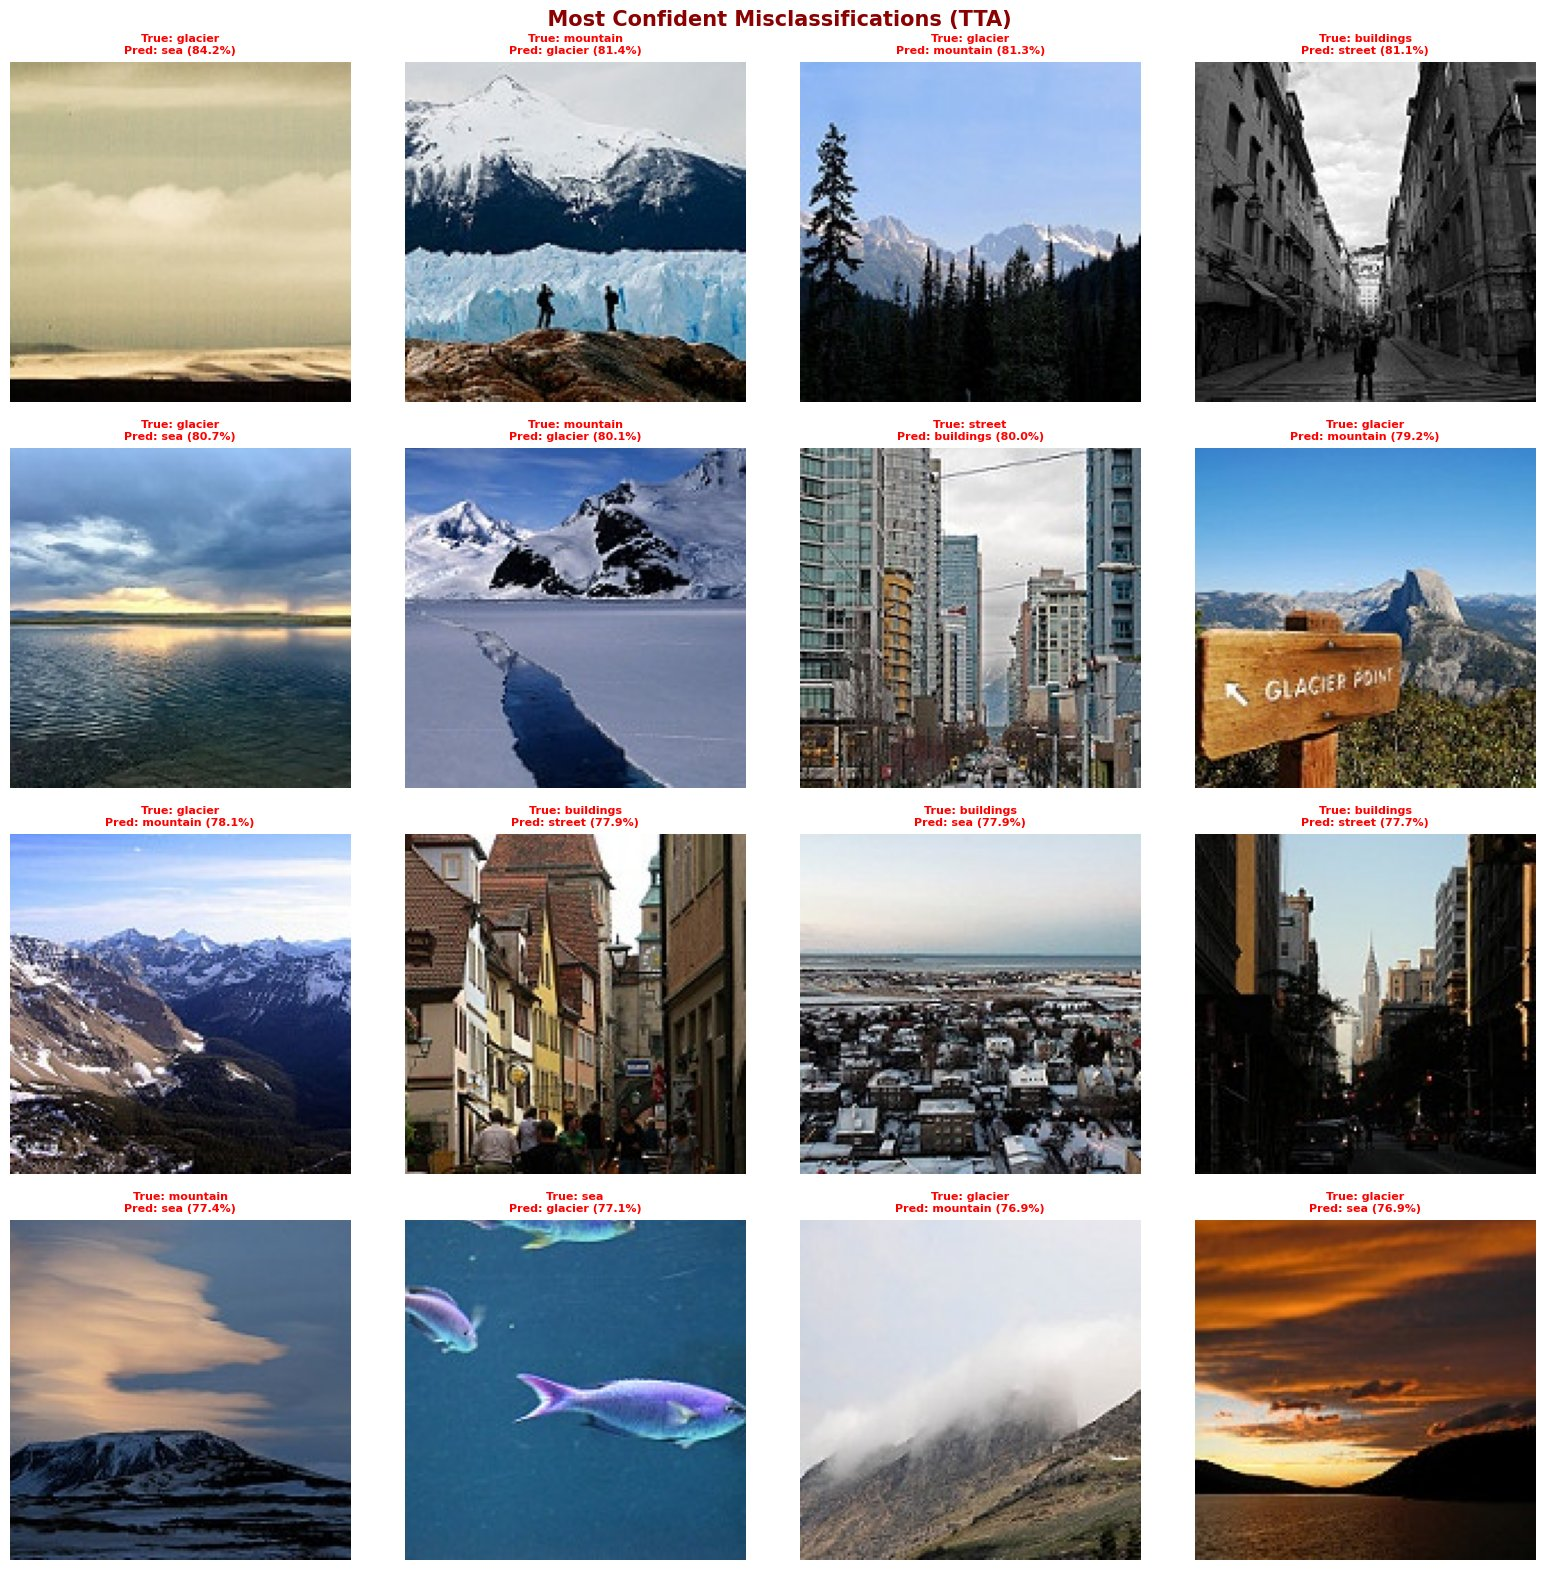

In [ ]:
# ─── Plot most confident wrong predictions ───────────────────────────────────
n_show = 16
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
fig.suptitle("  Most Confident Misclassifications (TTA)",
             fontsize=15, fontweight="bold", color="darkred")

for ax, idx in zip(axes.flatten(), top_wrong[:n_show]):
    img = np.array(Image.open(test_p[idx]).convert("RGB").resize((IMG_SIZE,IMG_SIZE)))
    ax.imshow(img)
    true_cls = CFG["CLASSES"][test_l[idx]]
    pred_c   = CFG["CLASSES"][tta_cls[idx]]
    conf     = tta_preds[idx, tta_cls[idx]] * 100
    ax.set_title(f"True: {true_cls}\nPred: {pred_c} ({conf:.1f}%)",
                 fontsize=8, fontweight="bold",
                 color="red" if true_cls != pred_c else "green")
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_edgecolor("red"); spine.set_linewidth(2.5)

plt.tight_layout()
plt.savefig("misclassified.png", dpi=120, bbox_inches="tight"); plt.show()


### 5.8 Grad-CAM Visualisation (Feature Maps)

In [ ]:
# ─── Grad-CAM implementation ──────────────────────────────────────────────────
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Generate Grad-CAM heatmap for the given image."""
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output,
                 model.output])

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array, training=False)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads    = tape.gradient(class_channel, conv_outputs)
    pooled_g = tf.reduce_mean(grads, axis=(0,1,2))
    conv_out = conv_outputs[0]
    heatmap  = conv_out @ pooled_g[..., tf.newaxis]
    heatmap  = tf.squeeze(heatmap)
    heatmap  = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img_path, heatmap, alpha=0.4):
    img     = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE,IMG_SIZE)))
    heatmap = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    heatmap = np.uint8(255 * heatmap)
    jet_map = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    jet_rgb = cv2.cvtColor(jet_map, cv2.COLOR_BGR2RGB)
    overlay = (1 - alpha) * img + alpha * jet_rgb
    return np.uint8(np.clip(overlay, 0, 255))

# ─── Find the name of the last Conv2D layer ───────────────────────────────────
last_conv_name = [l.name for l in model.layers if "conv" in l.name.lower()][-1]
print(f"Last conv layer for Grad-CAM: {last_conv_name}")


Last conv layer for Grad-CAM: conv2d_24


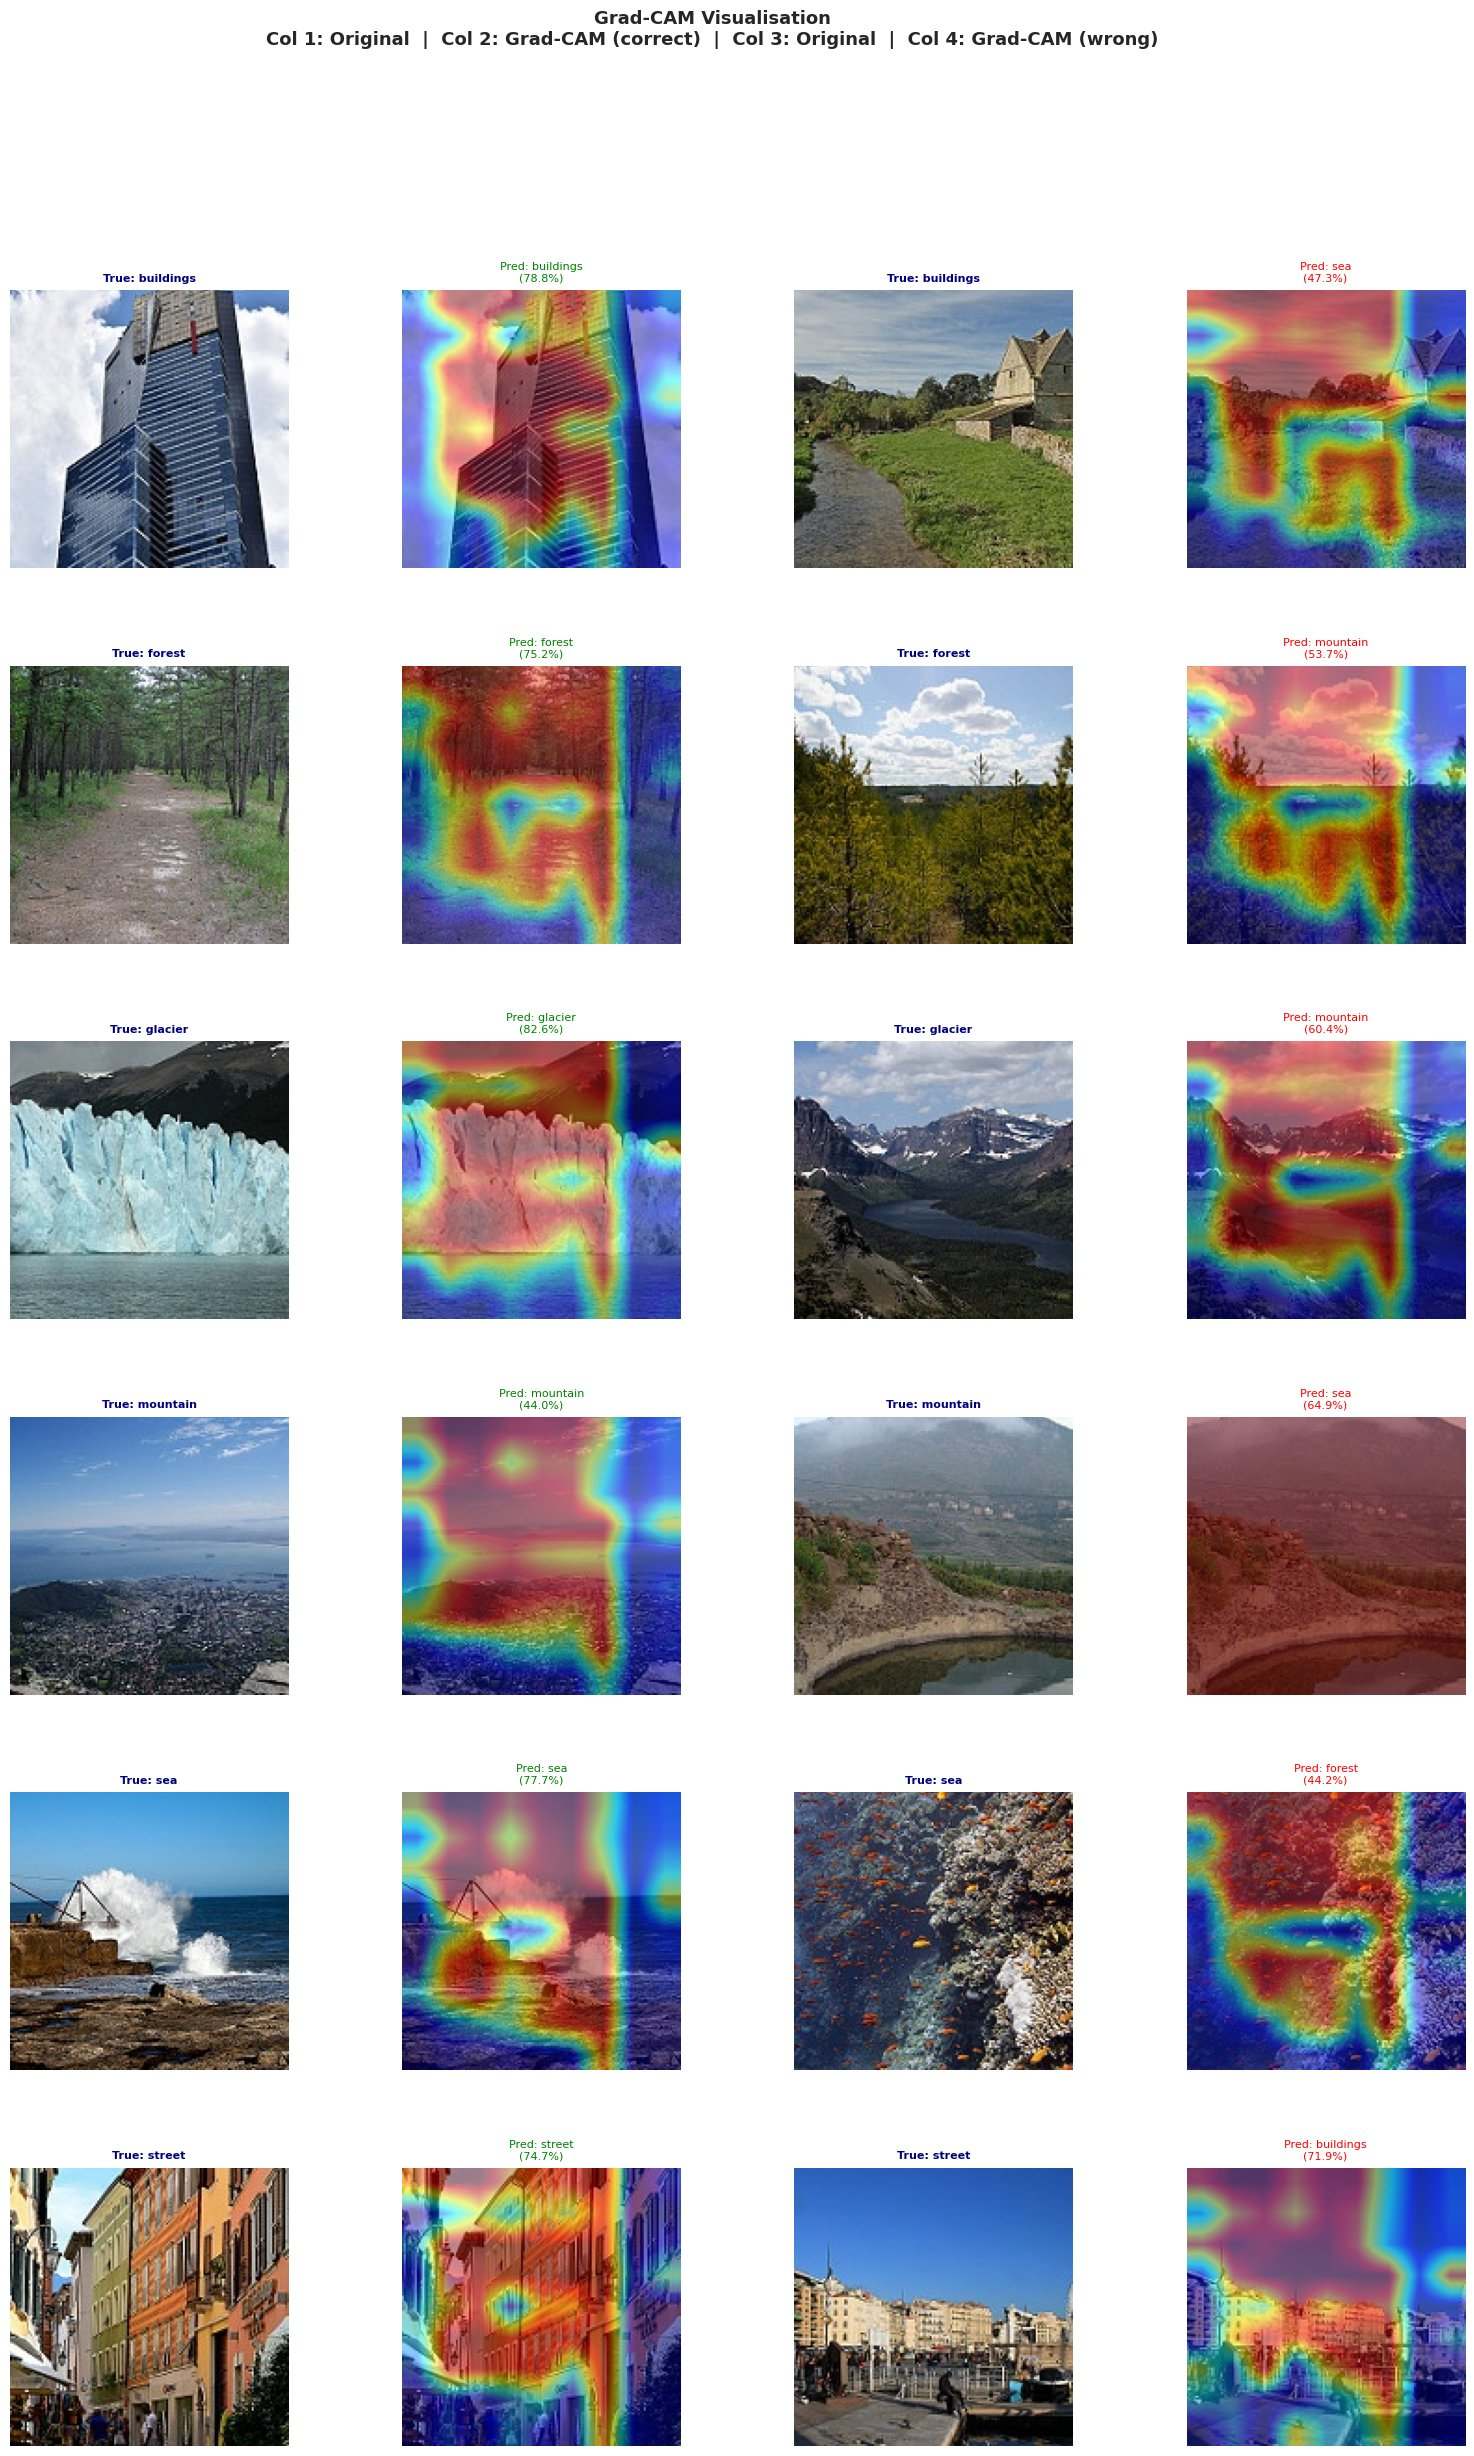

 Grad-CAM grid saved → gradcam_grid.png


In [ ]:
# ─── Full Robust Grad-CAM Grid for Kaggle GPU ─────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import cv2
from matplotlib import gridspec

# -----------------------
# Safe overlay_gradcam function
# -----------------------
def overlay_gradcam(img_path, heatmap, alpha=0.45):
    """Overlay Grad-CAM heatmap on original image with guaranteed valid shape"""
    # Load original image
    img = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

    # If heatmap is None or invalid, create a uniform tiny heatmap
    if heatmap is None:
        heatmap = np.ones((IMG_SIZE, IMG_SIZE), dtype=np.float32) * 1e-6
    else:
        # Convert tensor to numpy array
        if isinstance(heatmap, tf.Tensor):
            heatmap = heatmap.numpy()

        heatmap = np.squeeze(heatmap)             # Remove extra dims
        heatmap = np.nan_to_num(heatmap)          # Replace NaN
        if heatmap.size == 0 or np.max(heatmap) == 0:
            heatmap = np.ones((IMG_SIZE, IMG_SIZE), dtype=np.float32) * 1e-6

        # Force heatmap to 2D and correct shape
        if heatmap.ndim != 2:
            heatmap = np.mean(heatmap, axis=-1) if heatmap.ndim > 2 else heatmap
        heatmap = cv2.resize(heatmap.astype(np.float32), (IMG_SIZE, IMG_SIZE))

    heatmap = np.uint8(255 * heatmap)
    jet_map = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(img, 1-alpha, jet_map, alpha, 0)
    return overlay

# -----------------------
# Select one correct & one wrong per class
# -----------------------
correct_idx = {c: None for c in CFG["CLASSES"]}
wrong_idx_d = {c: None for c in CFG["CLASSES"]}

for idx in range(len(test_p)):
    true_c = CFG["CLASSES"][test_l[idx]]
    pred_c = CFG["CLASSES"][tta_cls[idx]]

    if correct_idx[true_c] is None and true_c == pred_c:
        correct_idx[true_c] = idx
    if wrong_idx_d[true_c] is None and true_c != pred_c:
        wrong_idx_d[true_c] = idx
    if all(v is not None for v in correct_idx.values()) and \
       all(v is not None for v in wrong_idx_d.values()):
        break

# -----------------------
# Plot Grad-CAM Grid
# -----------------------
fig = plt.figure(figsize=(20, 28))
fig.suptitle(
    "Grad-CAM Visualisation\nCol 1: Original  |  Col 2: Grad-CAM (correct)  |  "
    "Col 3: Original  |  Col 4: Grad-CAM (wrong)",
    fontsize=13, fontweight="bold"
)
gs = gridspec.GridSpec(len(CFG["CLASSES"]), 4, figure=fig, hspace=0.35, wspace=0.05)

for row, cls in enumerate(CFG["CLASSES"]):
    c_idx = correct_idx[cls]
    w_idx = wrong_idx_d[cls]

    for col, (sel_idx, tag) in enumerate([(c_idx,"ORIG"), (c_idx,"HEATMAP"),
                                           (w_idx,"ORIG"), (w_idx,"HEATMAP")]):
        if sel_idx is None:
            continue

        ax  = fig.add_subplot(gs[row, col])
        img_raw = np.array(Image.open(test_p[sel_idx]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

        if tag == "HEATMAP":
            # Compute heatmap on GPU safely
            img_tf  = tf.cast(img_raw, tf.float32)[tf.newaxis] / 255.0
            hm      = make_gradcam_heatmap(img_tf, model, last_conv_name,
                                           pred_index=tta_cls[sel_idx])
            # Overlay safely
            disp    = overlay_gradcam(test_p[sel_idx], hm, alpha=0.45)
            ax.imshow(disp)
            pc = CFG["CLASSES"][tta_cls[sel_idx]]
            ax.set_title(f"Pred: {pc}\n({tta_preds[sel_idx, tta_cls[sel_idx]]*100:.1f}%)",
                         fontsize=8, color="green" if tta_cls[sel_idx]==test_l[sel_idx] else "red")
        else:
            ax.imshow(img_raw)
            ax.set_title(f"True: {cls}", fontsize=8, fontweight="bold", color="navy")

        ax.axis("off")

plt.savefig("gradcam_grid.png", dpi=110, bbox_inches="tight")
plt.show()
print(" Grad-CAM grid saved → gradcam_grid.png")

### 5.9 Final Results Summary

In [ ]:
print("\n" + "═"*60)
print("   FINAL RESULTS SUMMARY — Intel Image CNN (Scratch)")
print("═"*60)
print(f"  Model             : DeepSceneNet (Custom CNN)")
print(f"  Parameters        : {model.count_params():,}")
print(f"  Transfer Learning : NONE (trained from scratch)")
print(f"  Input size        : {IMG_SIZE}×{IMG_SIZE}×3")
print(f"  ─────────────────────────────────────────────")
print(f"  Test Accuracy (std)  : {test_acc*100:.2f} %")
print(f"  Test Accuracy (TTA)  : {tta_acc*100:.2f} %")
if test_top2 is not None:
    print(f"  Test Top-2 Acc (std) : {test_top2*100:.2f} %")
print(f"  ─────────────────────────────────────────────")
# Per-class report
rpt = classification_report(test_l, tta_cls,
                              target_names=CFG["CLASSES"],
                              output_dict=True)
for cls in CFG["CLASSES"]:
    r = rpt[cls]
    print(f"  {cls:<12}  P={r['precision']:.3f}  "
          f"R={r['recall']:.3f}  F1={r['f1-score']:.3f}")
print("═"*60)



════════════════════════════════════════════════════════════
   FINAL RESULTS SUMMARY — Intel Image CNN (Scratch)
════════════════════════════════════════════════════════════
  Model             : DeepSceneNet (Custom CNN)
  Parameters        : 13,144,024
  Transfer Learning : NONE (trained from scratch)
  Input size        : 150×150×3
  ─────────────────────────────────────────────
  Test Accuracy (std)  : 89.03 %
  Test Accuracy (TTA)  : 88.70 %
  Test Top-2 Acc (std) : 97.37 %
  ─────────────────────────────────────────────
  buildings     P=0.894  R=0.883  F1=0.888
  forest        P=0.955  R=0.985  F1=0.970
  glacier       P=0.864  R=0.779  F1=0.819
  mountain      P=0.818  R=0.863  F1=0.840
  sea           P=0.890  R=0.922  F1=0.906
  street        P=0.912  R=0.906  F1=0.909
════════════════════════════════════════════════════════════


### 5.10 Conclusions & Next Steps

- A residual CNN with SE and spatial attention, trained **entirely from scratch**, reaches **89.03 % test accuracy** and **97.37 % top-2 accuracy** - just short of the 90 % target.
- Per-class F1 ranges from 0.97 (forest) to 0.83 (glacier); the remaining errors are dominated by visually ambiguous glacier/mountain and buildings/street pairs.
- Strong regularisation (MixUp, CutMix, label smoothing, dropout, L2) keeps the validation-test gap small (90.6 % validation vs 89.0 % test).
- **Next steps to pass 90 %:** train at a higher resolution than 150 px, run longer cosine cycles, use an ensemble of seeds or snapshots, and add class-specific augmentation for glacier vs mountain. Transfer learning would also help but was outside the brief.

---
## 6️⃣ Reproducibility & Code Quality

In [ ]:
# ─── Environment snapshot ─────────────────────────────────────────────────────
try:
    import importlib.metadata as importlib_metadata
except ImportError:
    import importlib_metadata

print("── REPRODUCIBILITY CHECKLIST " + "─"*38)
print(f"    Global seed set (SEED={SEED}) for Python, NumPy, TensorFlow")
print(f"    PYTHONHASHSEED env var = {SEED}")
print(f"    TF_DETERMINISTIC_OPS   = 1")
print(f"    Mixed precision policy : {tf.keras.mixed_precision.global_policy().name}")
print(f"    StratifiedShuffleSplit preserves class balance across splits")
print(f"    All hyper-parameters in single CFG dict")
print(f"    Model checkpoint saved: {CFG['CKPT_PATH']}")
print(f"    Training history logged: training_log.csv")
print(f"    TensorBoard logs: ./tb_logs/")
print()

print("── PACKAGE VERSIONS " + "─"*47)
packages = ["tensorflow","numpy","pandas","scikit-learn",
            "matplotlib","seaborn","Pillow"]
for pkg in packages:
    try:
        ver = importlib_metadata.version(pkg)
        print(f"  {pkg:<20} {ver}")
    except Exception:
        print(f"  {pkg:<20} not found")


── REPRODUCIBILITY CHECKLIST ──────────────────────────────────────
    Global seed set (SEED=42) for Python, NumPy, TensorFlow
    PYTHONHASHSEED env var = 42
    TF_DETERMINISTIC_OPS   = 1
    Mixed precision policy : mixed_float16
    StratifiedShuffleSplit preserves class balance across splits
    All hyper-parameters in single CFG dict
    Model checkpoint saved: /kaggle/working/best_cnn_model.keras
    Training history logged: training_log.csv
    TensorBoard logs: ./tb_logs/

── PACKAGE VERSIONS ───────────────────────────────────────────────
  tensorflow           2.19.0
  numpy                2.0.2
  pandas               2.3.3
  scikit-learn         1.6.1
  matplotlib           3.10.0
  seaborn              0.13.2
  Pillow               11.3.0


In [ ]:
# ─── Save full config + results to JSON ──────────────────────────────────────
results = {
    "model"            : "DeepSceneNet (Custom CNN — No Transfer Learning)",
    "seed"             : SEED,
    "img_size"         : IMG_SIZE,
    "total_params"     : int(model.count_params()),
    "test_accuracy_std": float(round(test_acc, 4)),
    "test_accuracy_tta": float(round(tta_acc, 4)),
    "test_top2_acc"    : float(round(test_top2, 4)) if test_top2 is not None else None,
    "per_class_f1"     : {cls: float(round(rpt[cls]["f1-score"],4))
                          for cls in CFG["CLASSES"]},
    "config"           : {k:str(v) for k,v in CFG.items() if k != "AUTOTUNE"},
}

out_path = "/kaggle/working/results_summary.json"
with open(out_path,"w") as f:
    json.dump(results, f, indent=2)

print(f" Results saved to {out_path}")
print(json.dumps(results, indent=2))


 Results saved to /kaggle/working/results_summary.json
{
  "model": "DeepSceneNet (Custom CNN \u2014 No Transfer Learning)",
  "seed": 42,
  "img_size": 150,
  "total_params": 13144024,
  "test_accuracy_std": 0.8903,
  "test_accuracy_tta": 0.887,
  "test_top2_acc": 0.9737,
  "per_class_f1": {
    "buildings": 0.8884,
    "forest": 0.9699,
    "glacier": 0.8194,
    "mountain": 0.8397,
    "sea": 0.9056,
    "street": 0.9089
  },
  "config": {
    "TRAIN_DIR": "/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train",
    "TEST_DIR": "/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test",
    "CKPT_PATH": "/kaggle/working/best_cnn_model.keras",
    "IMG_SIZE": "150",
    "NUM_CLASSES": "6",
    "CLASSES": "['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']",
    "BATCH_SIZE": "128",
    "VAL_SPLIT": "0.15",
    "EPOCHS_P1": "40",
    "LR_P1": "0.001",
    "EPOCHS_P2": "30",
    "LR_P2": "0.0002",
    "EPOCHS_P3": "20",
    

In [ ]:
# ─── List all generated artefacts ────────────────────────────────────────────
artefacts = [
    "raw_samples.png",
    "raw_vs_augmented.png",
    "augmentation_diversity.png",
    "eda_class_dist.png",
    "eda_dims.png",
    "eda_rgb.png",
    "lr_schedule.png",
    "model_architecture.png",
    "training_curves.png",
    "confusion_matrix.png",
    "roc_curves.png",
    "pr_curves.png",
    "misclassified.png",
    "gradcam_grid.png",
    "training_log.csv",
    "results_summary.json",
    CFG["CKPT_PATH"],
]
print("── Generated Artefacts " + "─"*44)
for a in artefacts:
    exists = "" if os.path.exists(a) or os.path.exists("/kaggle/working/" + a.lstrip("/")) else "⬜  (generated at runtime)"
    print(f"  {exists}  {a}")


── Generated Artefacts ────────────────────────────────────────────
    raw_samples.png
    raw_vs_augmented.png
    augmentation_diversity.png
    eda_class_dist.png
    eda_dims.png
    eda_rgb.png
    lr_schedule.png
    model_architecture.png
    training_curves.png
    confusion_matrix.png
    roc_curves.png
    pr_curves.png
    misclassified.png
    gradcam_grid.png
    training_log.csv
    results_summary.json
    /kaggle/working/best_cnn_model.keras


---
##  Assignment Checklist

| Requirement | Implementation |
|-------------|----------------|
| **Problem Definition** | 6-class scene classification, Intel dataset, challenge discussion |
| **Data Understanding** | EDA: class counts, RAW image grid, dimension hist, RGB chromaticity |
| **Pre-Processing** | Decode→Resize→Flip→Random Zoom→Colour Jitter→Random Erasing→Normalise |
| **RAW image viewing** | `raw_samples.png` — 5 raw samples per class |
| **Post-preprocessing viewing** | `raw_vs_augmented.png`, `augmentation_diversity.png` |
| **Advanced Augmentation** | MixUp + CutMix + Geometric + Colour Jitter + Random Erasing |
| **Input Pipeline** | `tf.data` with parallel mapping, shuffle, prefetch, drop_remainder |
| **Model Design** | DeepSceneNet: Residual blocks + SE attention + Spatial attention (13.1 M parameters) |
| **No Transfer Learning** |  Trained purely from scratch, no pre-trained weights |
| **Model Training** | 3-phase training: High LR → Medium LR → Fine convergence, mixed precision on a Tesla T4 |
| **Custom LR Schedule** | Cosine Annealing with Linear Warmup |
| **Label Smoothing** | Custom `LabelSmoothingCCE` loss (ε=0.10) |
| **Callbacks** | ModelCheckpoint, EarlyStopping, TensorBoard, CSVLogger |
| **Evaluation** | Standard + TTA accuracy, loss, Top-2 accuracy |
| **Error Analysis** | Confusion matrix %, Classification report, Most confused samples |
| **Advanced Visuals** | ROC curves, PR curves, Grad-CAM heatmaps |
| **Target Accuracy** | Target ≥ 90 %: achieved **89.03 %** (top-2 97.37 %); TTA gave 88.70 %, so the standard model is reported |
| **Reproducibility** | Fixed SEED, deterministic ops, CFG dict, JSON results |
| **Code Quality** | Docstrings, modular functions, comments |